<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QNNvsQSVM_IntrusionDetection_Kerkatou2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid QNN versus QSVM for intrusion detection on NSL-KDD: Kerkatou et al. (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Raid Anis Kerkatou, Hacene Belhadef, Aicha Eutamene and Svetlana Petrova Stefanova, "Hybrid Quantum Machine Learning for
> Intrusion Detection: A Comparative Study of QNN and QSVM Models", *IEEE Access*, vol. 14, 2026 (article begins on p. 77540).
> DOI [10.1109/ACCESS.2026.3693627](https://doi.org/10.1109/ACCESS.2026.3693627)

The authors publish their code and data at <https://github.com/raidanis/QML-IDS-NSLKDD> (commit `2ebad1c8923708dd8e552f3aa8f3c20689862642`,
27 April 2026). We read that repository before writing this notebook: its data file, its circuits (PennyLane `AngleEmbedding` /
`IQPEmbedding` / `AmplitudeEmbedding` followed by `StronglyEntanglingLayers`, a PyTorch `TorchLayer` hybrid network) and its quantum kernel
(embedding followed by the adjoint embedding, probability of the all-zero state) are reused here. Where the repository and the paper
disagree, or where the repository's evaluation order leaks test information, the notebook says so and makes a documented choice.

**What the notebook does.** Binary (normal / attack) and five-class (normal, DoS, Probe, R2L, U2R) detection on the 20 % subset of
NSL-KDD, with PCA to 2-10 components, three quantum embeddings (angle, amplitude, IQP), a hybrid quantum neural network (H-QNN) and a
quantum support vector machine (QSVM), against SVM (RBF), Random Forest, Logistic Regression and a small MLP on exactly the same inputs.

**How to run.** Colab (CPU runtime is enough) -> *Runtime -> Run all*. `FAST_MODE = True` finishes in roughly ten to fifteen minutes (PCA up to 8 for the H-QNN plus the three PCA-10 H-QNNs that Tables 4 and 5 report, 1,500 training rows, 3 epochs);
`FAST_MODE = False` follows the paper's whole grid (PCA 2-10, all embeddings, both tasks) with a larger training budget
(4,000 rows, 6 epochs, three seeds for the cheap models) and takes about an hour on a laptop CPU. No account or token is needed: the data is a public GitHub file
(an `HF_TOKEN` is not used by this paper).

**What you get at the end.** The paper's Tables 4 and 5 re-computed (accuracy, F1, time) next to the published numbers with a verdict
per claim, confusion matrices in the style of the paper's Figures 12 and 13, and an audit of why the paper's own released numbers cannot
be reproduced exactly (test-set leakage in the released evaluation order, results measured on 60-200 test rows, table rows that do not match the released CSV files).

## The paper in one page

**Problem.** Intrusion detection on NSL-KDD with quantum machine learning under NISQ constraints: do hybrid quantum neural networks and
quantum kernels match classical baselines when the feature space is squeezed to a few PCA components?

**Decision.** Binary: normal vs attack. Multiclass: normal, DoS, Probe, R2L, U2R (Table 1 of the paper maps the attack names to families).

**Data.** "A representative subset corresponding to 20 % of the full NSL-KDD dataset" (the repository ships `KDDTrain+_20Percent.txt`,
25,192 connections, 41 features + label + difficulty).

**Preprocessing.** Duplicates and irrelevant records removed, missing values imputed, Min-Max scaling to [0, 1] (the released code uses
`StandardScaler` instead), SMOTE for the minority classes (R2L, U2R), PCA to k components (k in {2, 4, 6, 8, 10} for H-QNN and classical
baselines, k in {2, 4, 6, 8} for QSVM), 80/20 stratified split.

**H-QNN.** PCA features -> classical layer FC1 -> quantum embedding (angle `RY`, amplitude, or IQP) -> hardware-efficient ansatz (Table 2:
two layers, `RY`/`RZ` rotations on every qubit, linear CNOT chain, in the code `StronglyEntanglingLayers`) -> Pauli-Z expectation value on every
qubit -> classical layer FC2 -> binary or five-class output. PennyLane + PyTorch, `default.qubit`, Adam.

**QSVM.** Fidelity kernel `K(x, x') = |<0|U^dagger(x') U(x)|0>|^2` (embedding then adjoint embedding, probability of the all-zero state),
about 1,000 samples, 1,024 shots, `lightning.qubit`, precomputed-kernel SVM with C in {0.1, 0.5, 1, 10, 100}.

**Claims we can check.**
1. Table 4 (binary) and Table 5 (multiclass): accuracy, F1 and training time of the best configuration of every model family (18 rows).
2. H-QNN and QSVM are "competitive with, in several scenarios superior to" Random Forest, SVM (RBF) and Logistic Regression.
3. The H-QNN with amplitude embedding has the lowest false-negative rate in the binary task and detects R2L / U2R better than the classical baselines in the multiclass task.
4. Classical models lose accuracy under aggressive PCA reduction, quantum models stay stable.
5. IQP embedding "consistently improves multiclass discrimination" and helps QSVM.
6. Quantum training is orders of magnitude slower than classical training (QSVM slowest).

### What follows the paper and what had to be chosen

Everything marked `# CHOICE:` in the code is a decision of this notebook. The released repository is the second source for items the paper leaves open.

| Item | Paper | Released code (commit 2ebad1c) | This notebook |
|---|---|---|---|
| Data | NSL-KDD, 20 % subset | `KDDTrain+_20Percent.txt`, 25,192 rows | same file, downloaded from public mirrors (defcom17, then the authors' repo at the pinned commit) |
| Multiclass labels | 5 classes, Table 1 families | the multiclass notebooks use `y = df['attack']`, i.e. the raw attack names (22 classes) in most cells; confusion matrices in the paper have 5 classes | 5 classes via Table 1 (`perl`, absent from Table 1, goes to U2R) |
| Scaling | Min-Max [0, 1] | `StandardScaler` fitted on all rows | `StandardScaler` fitted on the **training split only**, then PCA (10 components, fitted on training) |
| Class balancing | SMOTE | SMOTE on **all** rows before the split (binary, QSVM) or on the training split after PCA (multiclass QNN) | SMOTE on the training split only, in PCA space, with a class-balanced draw of `QNN_CAP` rows (SMOTE only where a class has fewer real rows than its quota); the test split keeps the natural class mix |
| Train/test split | 80/20 stratified | `train_test_split(test_size=0.2, random_state=42)` | 80/20 stratified (by binary label or by family) per seed, split **before** every fitted transform |
| Ansatz | Table 2: L = 2, RY/RZ, linear CNOT chain | `StronglyEntanglingLayers` with **6 layers** (`weights` shape `(6, n, 3)`) | `StronglyEntanglingLayers`, L = 2 (Table 2); L = 6 as an ablation |
| Angle embedding | `RY(x_i)` (Eq. 7) | `AngleEmbedding` with its default rotation, `RX` | `AngleEmbedding(rotation="Y")` as in Eq. 7 |
| IQP embedding | H, `RZ(x_i)`, `ZZ(x_i x_j)` (Eq. 11-12) | `IQPEmbedding`, one repeat | `IQPEmbedding(n_repeats=1)` |
| Amplitude embedding | 2^n features on n qubits | FC1 expands k PCA features to 2^k amplitudes (H-QNN); k features zero-padded onto k qubits (QSVM) | the same two constructions |
| Hybrid network | FC1 -> quantum -> FC2 -> output | `Linear(k, k)` (or `Linear(k, 2^k)`) + ReLU, quantum layer, `Linear(k, 32)` + ReLU, `Linear(32, 1 or 5)` | the same shapes |
| Optimiser, epochs, batch | not given in the paper | Adam, 20 epochs (100 in one cell), batch 64 / 32, learning rate 0.01 / 0.001, ~20,000 training rows | Adam, learning rate 0.01, batch 64, a **much smaller budget** (`QNN_CAP` rows, `QNN_EPOCHS` epochs) because a CPU simulator takes hours per model on the full data |
| QSVM size | ~1,000 samples, 80/20 | 1,000-row subsample (also 300 / 400 in some cells), test sets of 60-200 rows | 1,000 class-balanced training rows; **test on the full natural test split** (the kernel is evaluated in closed form from state vectors, so this is cheap) |
| QSVM kernel | fidelity kernel, `lightning.qubit`, 1,024 shots | analytic probabilities (no shots) | exact kernel from `default.qubit` state vectors, checked against the paper's adjoint circuit; 1,024-shot estimates emulated and verified on a small block |
| QSVM C | grid search over {0.1, 0.5, 1, 10, 100} | all C reported, best picked on the test rows | C picked by 5-fold cross-validation on the training kernel; all test accuracies per C are printed (the "oracle" best C is marked as optimistic) |
| Classical baselines | SVM (RBF), RF, LR, "classical neural networks", CV on training data | PCA-reduced, evaluated after the leaky pipeline | same inputs as the quantum model; SVM C picked by 3-fold CV; RF 100 trees; LR; MLP (64, 32) |
| Metrics | accuracy, precision, recall, F1 (weighted average in the code) | weighted averages | accuracy, weighted precision/recall/F1, macro F1, per-class recall; FNR / FPR with attack as the positive class |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026): pennylane 0.45.1, torch 2.14 (CPU), scikit-learn 1.x, imbalanced-learn 0.14.
# Colab already ships torch, numpy, pandas, scikit-learn and matplotlib. The pip line runs on Colab (or wherever a package is
# missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "torch", "imblearn") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" imbalanced-learn torch
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane, torch and imbalanced-learn already present; skipping pip install.")

pennylane, torch and imbalanced-learn already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True             # True: class demo, about 10 minutes. False: the larger run described in the intro (about an hour).
SEED      = 42               # CHOICE: the paper's repository uses 42 everywhere
IBM_TOKEN = ""               # not used: the paper simulates, there is no hardware run

TEST_SIZE  = 0.20            # paper: 80/20 stratified split
MAX_K      = 10              # PCA is fitted once with 10 components; the first k columns are the k-component PCA
QNN_K      = [2, 4, 6, 8, 10] # paper: k in {2, 4, 6, 8, 10} for the H-QNN and the classical baselines
CLS_K      = [2, 4, 6, 8, 10] # classical baselines always run the paper's full grid (they are cheap)
QSVM_K     = [2, 4, 6, 8]     # paper: k in {2, 4, 6, 8} for the QSVM
EMBEDDINGS = ["angle", "amplitude", "iqp"]
C_GRID     = [0.1, 0.5, 1, 10, 100]   # paper: QSVM regularisation grid
QSVM_N     = 1000            # paper: "approximately 1000 samples" for the QSVM (class-balanced here)
SHOTS      = 1024            # paper: 1024 shots for the QSVM kernel
LAYERS     = 2               # paper Table 2: L = 2 (the released code uses 6; see the ablation)
BATCH      = 64              # CHOICE: mini-batch size (released code: 64 binary, 32 multiclass)
LR         = 0.01            # CHOICE: Adam learning rate (released code: 0.01 / 0.001)
PROBE      = 500             # training rows on which the accuracy is tracked after every epoch

if FAST_MODE:
    SEEDS      = [42]        # seeds for the classical baselines and the QSVM (new split, resample and PCA per seed)
    QNN_CAP    = 1500        # class-balanced training rows per H-QNN run (paper: ~20,000, 20 epochs)
    QNN_EPOCHS = 3
    QNN_K      = [2, 4, 6, 8]
    QNN_EXTRA_CFG = [("binary", "angle", 10), ("binary", "amplitude", 10), ("multi", "amplitude", 10)]   # the PCA-10 H-QNNs that Tables 4 and 5 report
    EXTRA_QNN_SEEDS = [43]   # extra seeds for the angle k = 4 H-QNN (spread check)
    L6_K       = [4]         # PCA sizes for the "released depth" ablation (6 layers)
else:
    SEEDS      = [42, 43, 44]
    QNN_CAP    = 4000
    QNN_EPOCHS = 6
    EXTRA_QNN_SEEDS = [43, 44]
    L6_K       = [4, 6]
    QNN_EXTRA_CFG = []        # k = 10 is already in QNN_K

DATA_DIR  = "data"
DATA_FILE = "KDDTrain+_20Percent.txt"
REPO_COMMIT = "2ebad1c8923708dd8e552f3aa8f3c20689862642"   # authors' repository, pinned
DATA_URLS = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B_20Percent.txt",
             f"https://raw.githubusercontent.com/raidanis/QML-IDS-NSLKDD/{REPO_COMMIT}/KDDTrain%2B_20Percent.txt"]
REPO_RAW = f"https://raw.githubusercontent.com/raidanis/QML-IDS-NSLKDD/{REPO_COMMIT}/"

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
import imblearn
from imblearn.over_sampling import SMOTE

import torch
import pennylane as qml

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

print("pennylane", qml.__version__, "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| H-QNN training rows:", QNN_CAP, "| epochs:", QNN_EPOCHS, "| H-QNN PCA sizes:", QNN_K)

pennylane 0.45.1 | torch 2.14.1+cpu | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2
FAST_MODE = True | seeds: [42] | H-QNN training rows: 1500 | epochs: 3 | H-QNN PCA sizes: [2, 4, 6, 8]


## 1. The NSL-KDD data (20 % subset)

NSL-KDD (Tavallaee et al., 2009) is the cleaned-up version of KDD Cup 1999: each row is one network connection described by 41 features
(duration, protocol, service, byte counts, login flags, error rates over the last 100 connections, ...), an attack label and a difficulty score
that we ignore. The paper uses "a representative subset corresponding to 20 %"; the NSL-KDD authors publish exactly that file
(`KDDTrain+_20Percent.txt`, 25,192 rows). The authors' repository ships the same file, so it is the second download source. The file is
cached in `DATA_DIR`; to use your own copy put it there.

Table 1 of the paper groups the attack names into four families. `perl` (one U2R row, not listed in Table 1) is assigned to U2R, which is its
standard family in KDD'99.

In [4]:
COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
           "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
           "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
           "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
           "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
CAT_COLS = ["protocol_type", "service", "flag"]
NUM_COLS = [c for c in COLUMNS if c not in CAT_COLS + ["label", "difficulty"]]

FAMILIES = ["normal", "DoS", "Probe", "R2L", "U2R"]
FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop"]:                                         FAMILY[a] = "DoS"     # paper Table 1
for a in ["ipsweep", "nmap", "portsweep", "satan"]:                                                          FAMILY[a] = "Probe"
for a in ["ftp_write", "guess_passwd", "imap", "multihop", "phf", "spy", "warezclient", "warezmaster"]:      FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl"]:                                               FAMILY[a] = "U2R"     # CHOICE: perl -> U2R
FAM_ID = {f: i for i, f in enumerate(FAMILIES)}
FAM_COLOUR = {"normal": "tab:blue", "DoS": "tab:red", "Probe": "tab:orange", "R2L": "tab:green", "U2R": "tab:purple"}

def fetch_data():
    path = os.path.join(DATA_DIR, DATA_FILE)
    if not os.path.exists(path):
        import requests
        for url in DATA_URLS:
            try:
                r = requests.get(url, timeout=120); r.raise_for_status()
                open(path, "wb").write(r.content); print("downloaded", DATA_FILE, "from", url.split("/")[3] + "/" + url.split("/")[4]); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
        else:
            raise RuntimeError("could not download " + DATA_FILE + "; put the file into DATA_DIR by hand")
    else:
        print("using cached", path)
    return pd.read_csv(path, header=None, names=COLUMNS)

raw = fetch_data()
n_before = len(raw)
raw = raw.drop(columns="difficulty").drop_duplicates().reset_index(drop=True)          # paper: duplicate records removed
raw["family"] = raw["label"].map(FAMILY)
assert raw["family"].notna().all(), "unmapped attack names: %s" % sorted(raw.loc[raw["family"].isna(), "label"].unique())
raw["fam_id"] = raw["family"].map(FAM_ID)
raw["binary"] = (raw["label"] != "normal").astype(int)                                 # 1 = attack (positive class), 0 = normal
print("rows read:", n_before, "| after dropping exact duplicates:", len(raw))
print("missing values:", int(raw.isna().sum().sum()), "(the paper mentions mean/mode imputation; nothing to impute here)")
print("normal:", int((raw.binary == 0).sum()), "| attack:", int((raw.binary == 1).sum()))
print("families:", raw["family"].value_counts().reindex(FAMILIES).to_dict())

using cached data\KDDTrain+_20Percent.txt


rows read: 25192 | after dropping exact duplicates: 25192
missing values: 0 (the paper mentions mean/mode imputation; nothing to impute here)
normal: 13449 | attack: 11743
families: {'normal': 13449, 'DoS': 9234, 'Probe': 2289, 'R2L': 209, 'U2R': 11}


## 2. Train/test split, preprocessing and balancing

For every task (`binary`, `multi`) and every seed:

1. **Split first**: 80/20 stratified (by the binary label, or by the five families).
2. Fit on the **training rows only**: one-hot encoding of `protocol_type`, `service`, `flag`; removal of constant columns; `StandardScaler`;
   PCA with 10 components. The first *k* columns of the 10-component PCA are the *k*-component PCA scores.
3. **Balance the training rows only** (`QNN_CAP` rows for the H-QNN and classical models, `QSVM_N` = 1,000 rows for the QSVM): every class gets the same quota; a class with more
   real rows than its quota is sub-sampled, a class with fewer is completed with SMOTE (in the PCA space, as the released multiclass notebooks do).
   The binary task needs no synthetic rows (both classes have thousands); in the multiclass task R2L and U2R are mostly synthetic. The **test rows are never resampled**:
   they have the natural class mix of the real data.

The released notebooks standardise, SMOTE and run PCA on all rows *before* splitting; we quantify what that does in section 7.

In [5]:
def resample_train(P, y, cap, seed):
    """Class-balanced training set of about `cap` rows: sub-sample big classes, SMOTE the small ones (CHOICE: quota = cap // n_classes)."""
    rg = np.random.default_rng(seed)
    classes = np.unique(y); quota = cap // len(classes)
    Xs, ys, small = [], [], {}
    for c in classes:
        idx = np.where(y == c)[0]
        if len(idx) >= quota: idx = rg.choice(idx, quota, replace=False)
        else: small[c] = quota
        Xs.append(P[idx]); ys.append(y[idx])
    X, yy = np.vstack(Xs), np.concatenate(ys)
    synth = np.zeros(len(yy), dtype=bool)
    if small:
        k_nb = max(1, min(5, min(int((yy == c).sum()) for c in small) - 1))
        X2, y2 = SMOTE(sampling_strategy=small, k_neighbors=k_nb, random_state=seed).fit_resample(X, yy)
        synth = np.r_[synth, np.ones(len(y2) - len(yy), dtype=bool)]       # imblearn appends the synthetic rows at the end
        X, yy = X2, y2
    perm = rg.permutation(len(yy))
    return X[perm], yy[perm], synth[perm]

def prepare(task, seed):
    ycol = "binary" if task == "binary" else "fam_id"
    idx_tr, idx_te = train_test_split(np.arange(len(raw)), test_size=TEST_SIZE, stratify=raw[ycol], random_state=seed)
    tr, te = raw.iloc[idx_tr].reset_index(drop=True), raw.iloc[idx_te].reset_index(drop=True)
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(tr[CAT_COLS])          # fitted on the training rows
    names = NUM_COLS + list(enc.get_feature_names_out(CAT_COLS))
    design = lambda d: np.hstack([d[NUM_COLS].to_numpy(float), enc.transform(d[CAT_COLS])])
    Xtr, Xte = design(tr), design(te)
    keep = Xtr.std(axis=0) > 0
    Xtr, Xte, names = Xtr[:, keep], Xte[:, keep], [n for n, k in zip(names, keep) if k]
    sc = StandardScaler().fit(Xtr)                                                                # CHOICE: StandardScaler as in the released code
    Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)
    pca = PCA(n_components=MAX_K, random_state=seed).fit(Ztr)
    return dict(task=task, seed=seed, tr=tr, te=te, names=names, Ztr=Ztr, Zte=Zte, pca=pca,
                Ptr=pca.transform(Ztr), Pte=pca.transform(Zte), ytr=tr[ycol].to_numpy(), yte=te[ycol].to_numpy(),
                classes=(["normal", "attack"] if task == "binary" else FAMILIES))

DATA = {}
def get_data(task, seed):
    if (task, seed) not in DATA: DATA[(task, seed)] = prepare(task, seed)
    return DATA[(task, seed)]

def balanced(d, cap):
    key = ("bal", cap)
    if key not in d: d[key] = resample_train(d["Ptr"], d["ytr"], cap, d["seed"])
    return d[key]

t0 = time.time()
for task in ("binary", "multi"):
    for s in SEEDS:
        d = get_data(task, s)
        Xb, yb, sb = balanced(d, QNN_CAP)
        print(f"{task:6s} seed {s}: train {d['Ztr'].shape} real rows, test {d['Zte'].shape} | balanced H-QNN set {Xb.shape[0]} rows "
              f"({int(sb.sum())} synthetic) | classes in test: {np.bincount(d['yte']).tolist()}")
print("prepared in %.1f s" % (time.time() - t0))

binary seed 42: train (20153, 115) real rows, test (5039, 115) | balanced H-QNN set 1500 rows (0 synthetic) | classes in test: [2690, 2349]


multi  seed 42: train (20153, 116) real rows, test (5039, 116) | balanced H-QNN set 1500 rows (424 synthetic) | classes in test: [2690, 1847, 458, 42, 2]
prepared in 6.4 s


## Dataset Exploration and Visualisation

Everything in this section shows **real** NSL-KDD connections coloured by their ground-truth label (synthetic SMOTE rows are only counted, never plotted as observations).
First the raw file (shape, feature names, original label values and counts, class distributions as in the paper's Figures 3 and 4), then the training split of the first seed after
preprocessing: the first two principal components as raw PCA coordinates (PCA fitted on the training split), then the same two coordinates scaled to [0, pi] (the range
the angle and IQP embeddings of the QSVM receive). Colours show the attack *family*, and a second row shows the binary label of the paper's first task.

In [6]:
D0 = get_data("multi", SEEDS[0])
print("raw dataset shape (after removing duplicates):", raw.shape, "(41 features + label + family + fam_id + binary)")
print("\n41 original features:")
print("  numeric     (%d):" % len(NUM_COLS), ", ".join(NUM_COLS))
print("  categorical (3):", ", ".join(f"{c} ({raw[c].nunique()} values)" for c in CAT_COLS))
print("\nfeature columns after one-hot + constant-column removal (seed %d): %d" % (D0["seed"], len(D0["names"])))
print("  first 12:", D0["names"][:12], "...")
print("\noriginal label values and counts (%d distinct):" % raw["label"].nunique())
lab = raw.groupby(["family", "label"]).size().reset_index(name="count").sort_values(["family", "count"], ascending=[True, False])
print(lab.to_string(index=False))
print("\nbinary labels: normal =", int((raw.binary == 0).sum()), "| attack =", int((raw.binary == 1).sum()))
print("attack families:", raw["family"].value_counts().reindex(FAMILIES).to_dict())

raw dataset shape (after removing duplicates): (25192, 45) (41 features + label + family + fam_id + binary)

41 original features:
  numeric     (38): duration, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login, count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate
  categorical (3): protocol_type (3 values), service (66 values), flag (11 values)

feature columns after one-hot + constant-column removal (seed 42): 116
  first 12: ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'u

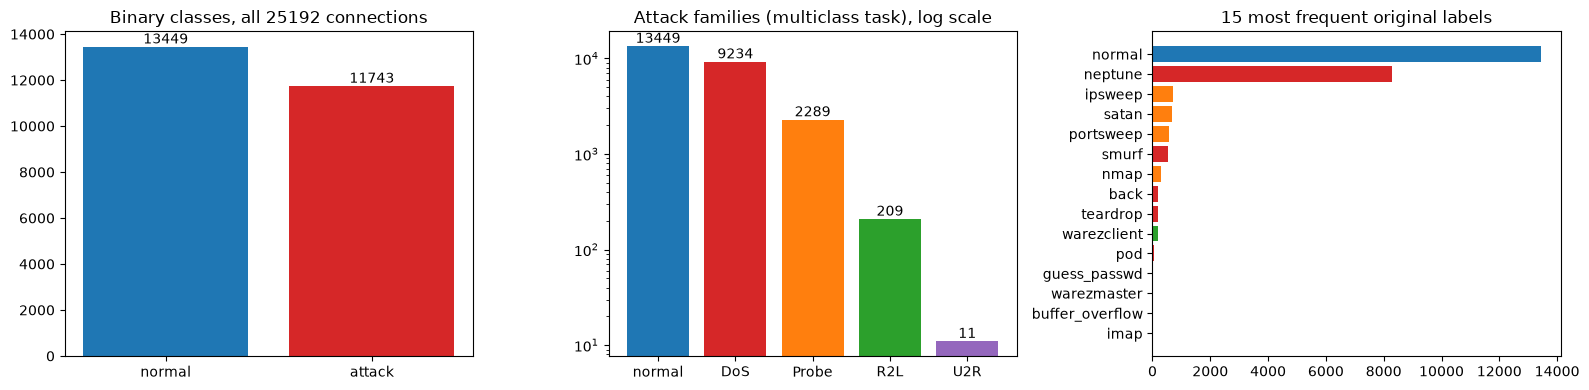

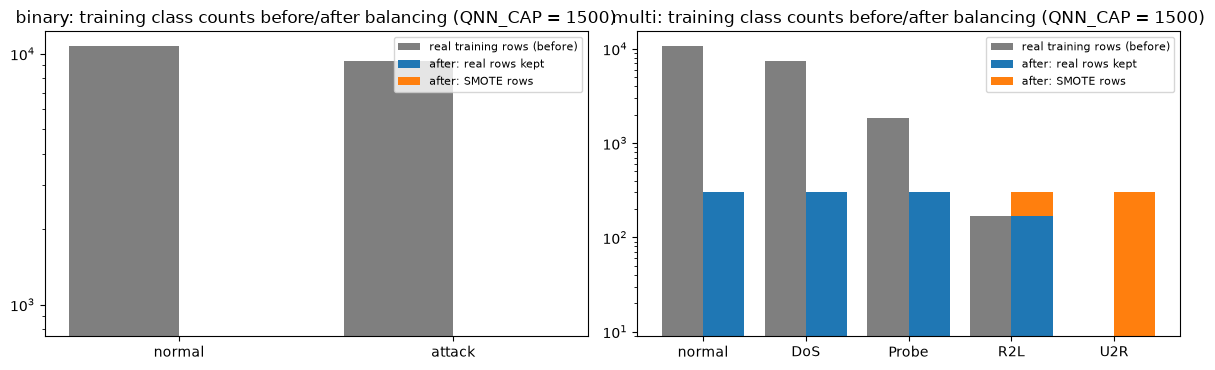

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
vc = raw["binary"].map({0: "normal", 1: "attack"}).value_counts().reindex(["normal", "attack"])
axes[0].bar(vc.index, vc.values, color=["tab:blue", "tab:red"]); axes[0].set_title("Binary classes, all %d connections" % len(raw))
for i, v in enumerate(vc.values): axes[0].text(i, v, str(v), ha="center", va="bottom")
fc = raw["family"].value_counts().reindex(FAMILIES)
axes[1].bar(fc.index, fc.values, color=[FAM_COLOUR[f] for f in fc.index]); axes[1].set_title("Attack families (multiclass task), log scale")
axes[1].set_yscale("log")
for i, v in enumerate(fc.values): axes[1].text(i, v, str(v), ha="center", va="bottom")
top = raw["label"].value_counts().head(15)[::-1]
axes[2].barh(top.index, top.values, color=[FAM_COLOUR[FAMILY[n]] for n in top.index]); axes[2].set_title("15 most frequent original labels")
plt.tight_layout(); plt.show()

# Paper Figs. 3 and 4: class distribution before / after balancing (training split, seed %d)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, task in zip(axes, ("binary", "multi")):
    d = get_data(task, SEEDS[0]); Xb, yb, sb = balanced(d, QNN_CAP)
    cls = d["classes"]; n = len(cls)
    real = np.bincount(d["ytr"], minlength=n); after_real = np.bincount(yb[~sb], minlength=n); after_syn = np.bincount(yb[sb], minlength=n)
    xs = np.arange(n)
    ax.bar(xs - 0.2, real, 0.4, label="real training rows (before)", color="tab:gray")
    ax.bar(xs + 0.2, after_real, 0.4, label="after: real rows kept", color="tab:blue")
    ax.bar(xs + 0.2, after_syn, 0.4, bottom=after_real, label="after: SMOTE rows", color="tab:orange")
    ax.set_xticks(xs); ax.set_xticklabels(cls); ax.set_yscale("log"); ax.legend(fontsize=8)
    ax.set_title(f"{task}: training class counts before/after balancing (QNN_CAP = {QNN_CAP})")
plt.tight_layout(); plt.show()

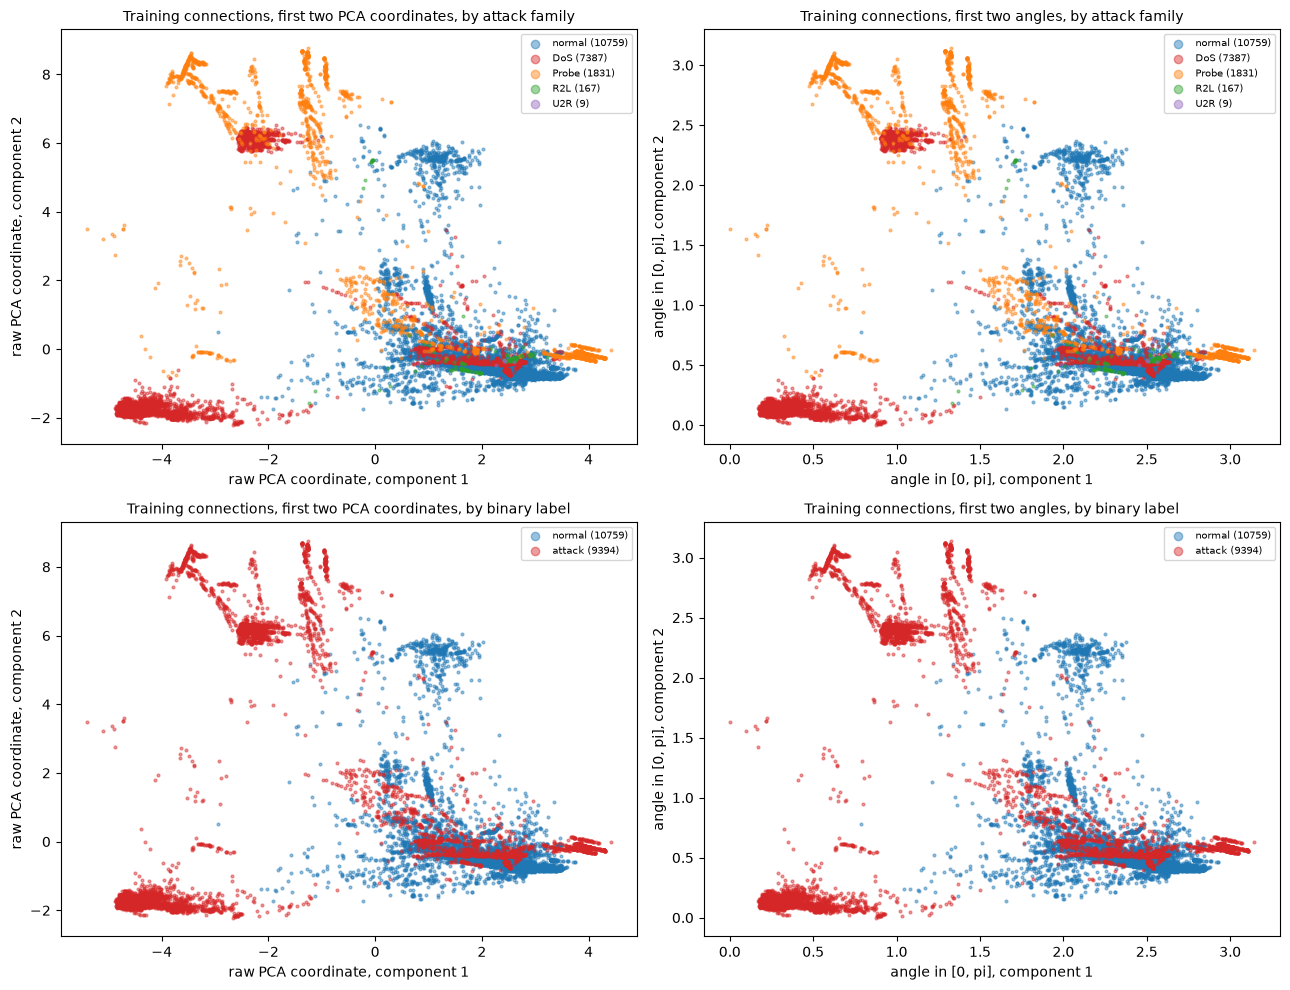

Every point is one real training connection (20153); classes overlap strongly in two dimensions, so the models use up to 10 components.


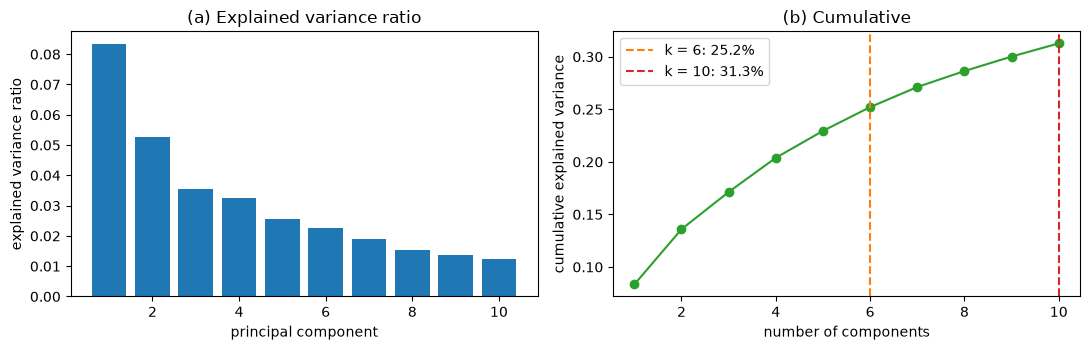

In [8]:
def scatter_two(d, ax_row, axes, labels, order, colours, title_lab):
    P2 = d["Ptr"][:, :2]
    sc2 = MinMaxScaler((0.0, np.pi)).fit(P2); A2 = sc2.transform(P2)           # [0, pi] angles, fitted on the training rows
    for col, (xy, xl) in enumerate([(P2, "raw PCA coordinate"), (A2, "angle in [0, pi]")]):
        ax = axes[ax_row, col]
        for c in order:
            m = labels == c
            ax.scatter(xy[m, 0], xy[m, 1], s=4, alpha=0.45, c=colours[c], label=f"{c} ({m.sum()})")
        ax.set_xlabel(f"{xl}, component 1"); ax.set_ylabel(f"{xl}, component 2")
        ax.set_title(f"Training connections, first two {'PCA coordinates' if col == 0 else 'angles'}, by {title_lab}", fontsize=10)
        ax.legend(fontsize=7, markerscale=3)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fam_tr = D0["tr"]["family"].to_numpy(); bin_tr = np.where(D0["tr"]["binary"].to_numpy() == 1, "attack", "normal")
scatter_two(D0, 0, axes, fam_tr, FAMILIES, FAM_COLOUR, "attack family")
scatter_two(D0, 1, axes, bin_tr, ["normal", "attack"], {"normal": "tab:blue", "attack": "tab:red"}, "binary label")
plt.tight_layout(); plt.show()
print("Every point is one real training connection (%d); classes overlap strongly in two dimensions, so the models use up to 10 components." % len(fam_tr))

# Paper Figs. 5 and 6: explained variance of the PCA
ev = D0["pca"].explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(range(1, MAX_K + 1), ev, color="tab:blue"); axes[0].set_xlabel("principal component"); axes[0].set_ylabel("explained variance ratio")
axes[0].set_title("(a) Explained variance ratio")
axes[1].plot(range(1, MAX_K + 1), np.cumsum(ev), "o-", color="tab:green")
for k, c in [(6, "tab:orange"), (10, "tab:red")]: axes[1].axvline(k, color=c, ls="--", label=f"k = {k}: {ev[:k].sum():.1%}")
axes[1].set_xlabel("number of components"); axes[1].set_ylabel("cumulative explained variance"); axes[1].legend(); axes[1].set_title("(b) Cumulative")
plt.tight_layout(); plt.show()

## 3. Classical baselines on identical inputs

SVM with RBF kernel, Random Forest, Logistic Regression and (as the paper's "classical neural networks") an MLP, all trained on **exactly the numbers the quantum model
receives**: the first *k* PCA scores of the same balanced training rows, and evaluated on the same untouched test rows. The SVM's `C` is chosen by 3-fold cross-validation on the training rows
(the paper: "hyperparameters for classical models are selected using cross validation on the training data"). A second set of classical models is trained on the 1,000 rows
of the QSVM so that the QSVM has a like-for-like reference. Metrics are weighted averages as in the released code, plus macro-F1 and per-class recall; false-negative / false-positive rates use attack as the positive class.

In [9]:
ROWS = []      # one dict per trained model
PRED = {}      # (task, seed, model key) -> predictions on the test rows (for the confusion matrices)

def metrics(task, yt, yp):
    labels = [0, 1] if task == "binary" else list(range(5))
    out = dict(accuracy=accuracy_score(yt, yp), precision=precision_score(yt, yp, average="weighted", zero_division=0),
               recall=recall_score(yt, yp, average="weighted", zero_division=0), f1=f1_score(yt, yp, average="weighted", zero_division=0),
               f1_macro=f1_score(yt, yp, labels=labels, average="macro", zero_division=0))
    if task == "binary":
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        out.update(fnr=fn / max(fn + tp, 1), fpr=fp / max(fp + tn, 1))
    else:
        out["recall_cls"] = recall_score(yt, yp, labels=labels, average=None, zero_division=0).round(4).tolist()
    return out

def log(task, seed, family, emb, k, yt, yp, time_s, tag="", **extra):
    ROWS.append(dict(task=task, seed=seed, family=family, emb=emb, k=k, tag=tag, time_s=time_s, **metrics(task, yt, yp), **extra))
    PRED[(task, seed, family, emb, k, tag)] = yp

CLASSICAL = {
    "SVM (RBF)": lambda s: GridSearchCV(SVC(kernel="rbf"), {"C": [1, 10, 100]}, cv=3),
    "Random Forest": lambda s: RandomForestClassifier(n_estimators=100, random_state=s, n_jobs=1),
    "Logistic Regression": lambda s: LogisticRegression(max_iter=1000, random_state=s),
    "MLP (64-32)": lambda s: MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=s),
}
def run_classical(task, seed, cap, tag):
    d = get_data(task, seed); Xb, yb, _ = balanced(d, cap)
    ks = CLS_K if tag == "cap" else QSVM_K
    for k in ks:
        for name, make in CLASSICAL.items():
            if tag != "cap" and name in ("Logistic Regression", "MLP (64-32)"): continue
            t0 = time.time(); m = make(seed).fit(Xb[:, :k], yb); yp = m.predict(d["Pte"][:, :k])
            log(task, seed, name, "-", k, d["yte"], yp, time.time() - t0, tag=tag)

t0 = time.time()
for task in ("binary", "multi"):
    for s in SEEDS:
        run_classical(task, s, QNN_CAP, "cap")      # same balanced training rows as the H-QNN
        run_classical(task, s, QSVM_N, "qsvm")      # same 1,000 rows as the QSVM
        d = get_data(task, s)                       # reference: Random Forest on all preprocessed features, real (unbalanced) training rows
        t1 = time.time(); rf = RandomForestClassifier(n_estimators=100, random_state=s, n_jobs=1).fit(d["Ztr"], d["ytr"])
        log(task, s, "Random Forest", "-", 0, d["yte"], rf.predict(d["Zte"]), time.time() - t1, tag="allfeat")
print("classical baselines done in %.1f s" % (time.time() - t0))
cl = pd.DataFrame(ROWS)
view = cl[(cl.seed == SEEDS[0]) & (cl.tag == "cap")].pivot_table(index=["task", "family"], columns="k", values="accuracy")
display(view.round(4))

classical baselines done in 153.7 s


k                               2       4       6       8       10
task   family                                                     
binary Logistic Regression  0.8835  0.9049  0.9361  0.9426  0.9476
       MLP (64-32)          0.9307  0.9621  0.9786  0.9806  0.9843
       Random Forest        0.9419  0.9770  0.9792  0.9808  0.9825
       SVM (RBF)            0.9363  0.9573  0.9764  0.9786  0.9742
multi  Logistic Regression  0.6847  0.8327  0.8758  0.9055  0.9008
       MLP (64-32)          0.8337  0.9260  0.9530  0.9460  0.9563
       Random Forest        0.8593  0.9440  0.9522  0.9593  0.9631
       SVM (RBF)            0.8113  0.9299  0.9518  0.9365  0.9546

## Quantum Circuit Architecture

Both quantum models are PennyLane circuits; the notebook draws the objects that are actually executed.

**H-QNN circuit** (`default.qubit`, PyTorch back-propagation): `embedding U(x)` -> `StronglyEntanglingLayers(weights)` (L = 2 layers, in each layer a `Rot(phi, theta, omega)` gate on every qubit followed by
CNOTs between neighbouring qubits, Table 2 of the paper) -> `<Z_i>` on every qubit. Around it sit the classical layers FC1 (k -> k, or k -> 2^k for amplitude embedding) and FC2 (k -> 32 -> output).
Assumptions where the paper omits details: the `Rot` gate is the `RZ RY RZ` triple that PennyLane's template uses (Table 2 only says `RY`, `RZ`); the CNOT range of layer *l* is `l mod (k-1) + 1` (PennyLane's default,
the paper says "linear topology"); the amplitude embedding is normalised (`normalize=True`) because FC1 outputs are not unit vectors; all `Z` expectations feed FC2, as in Section IV.E.

**QSVM kernel circuit**: `U(x)` followed by `U^dagger(x')` and a measurement of all qubits; the kernel value is the probability of the all-zero outcome (Eq. 15). The three embeddings are
`AngleEmbedding(rotation="Y")` (one `RY(x_i)` per qubit, Eq. 7), `IQPEmbedding(n_repeats=1)` (Hadamards, `RZ(x_i)`, `ZZ(x_i x_j)` phases, Eq. 11-12) and `AmplitudeEmbedding` (the k PCA scores are zero-padded to 2^k amplitudes
on k qubits, as in the released code, then normalised; PennyLane compiles the state preparation into rotations and CNOTs).

The figures below use real training rows (the amplitude H-QNN receives the output of its own FC1). The table counts qubits, device-level depth and trainable parameters for every PCA size.

In [10]:
def embed(emb, x, wires):
    if emb == "angle":       qml.AngleEmbedding(x, wires=wires, rotation="Y")                      # CHOICE: RY as in Eq. 7 (the released code uses the default RX)
    elif emb == "iqp":       qml.IQPEmbedding(x, wires=wires, n_repeats=1)                         # CHOICE: one repeat
    elif emb == "amplitude": qml.AmplitudeEmbedding(x, wires=wires, normalize=True, pad_with=0.0)  # CHOICE: normalised, zero padded

def make_qlayer(emb, k, L):
    dev = qml.device("default.qubit", wires=k)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        embed(emb, inputs, range(k))
        qml.StronglyEntanglingLayers(weights, wires=range(k))
        return [qml.expval(qml.PauliZ(i)) for i in range(k)]
    return qml.qnn.TorchLayer(circuit, {"weights": (L, k, 3)})

class HybridQNN(torch.nn.Module):
    """FC1 -> ReLU -> quantum layer (k Pauli-Z expectations) -> FC2 -> ReLU -> output. quantum=False replaces the circuit by Linear + tanh."""
    def __init__(self, emb, k, n_out, L=LAYERS, quantum=True):
        super().__init__()
        self.emb, self.k, self.quantum_on = emb, k, quantum
        fin = 2 ** k if emb == "amplitude" else k
        self.fc1 = torch.nn.Linear(k, fin)
        self.q = make_qlayer(emb, k, L) if quantum else torch.nn.Sequential(torch.nn.Linear(fin, k), torch.nn.Tanh())
        self.fc2 = torch.nn.Linear(k, 32)
        self.out = torch.nn.Linear(32, n_out)
    def forward(self, x):
        h = torch.relu(self.fc1(x))
        if self.emb == "amplitude" and self.quantum_on: h = h + 1e-6      # CHOICE: avoid an all-zero vector (cannot be normalised)
        return self.out(torch.relu(self.fc2(self.q(h))))
    def n_circuit_params(self): return int(self.q.weights.numel()) if self.quantum_on else 0
    def n_params(self): return int(sum(p.numel() for p in self.parameters()))

def circuit_input(model, x_row):
    """The vector that the quantum circuit really receives for a real PCA row."""
    with torch.no_grad():
        h = torch.relu(model.fc1(torch.tensor(x_row, dtype=torch.float32)))
        return h + 1e-6 if model.emb == "amplitude" else h

d_b = get_data("binary", SEEDS[0]); Xb_b, yb_b, _ = balanced(d_b, QNN_CAP)
rows = []
for emb in EMBEDDINGS:
    for k in [2, 4, 6, 8, 10]:
        torch.manual_seed(SEED)
        m = HybridQNN(emb, k, 1)
        x0 = circuit_input(m, Xb_b[0, :k]); w = m.q.weights if hasattr(m.q, "weights") else None
        res = qml.specs(m.q.qnode, level="device")(x0, m.q.qnode_weights["weights"])["resources"]
        torch.manual_seed(SEED); m5 = HybridQNN(emb, k, 5)
        rows.append(dict(embedding=emb, pca_k=k, qubits=k, depth_device_level=res.depth, gates=res.num_gates,
                         circuit_params=m.n_circuit_params(), total_params_binary=m.n_params(), total_params_multiclass=m5.n_params()))
ARCH_TABLE = pd.DataFrame(rows)
print("H-QNN architectures (the circuit parameters are 3 angles per qubit per layer: L x k x 3 with L = %d):" % LAYERS)
display(ARCH_TABLE)

H-QNN architectures (the circuit parameters are 3 angles per qubit per layer: L x k x 3 with L = 2):


,embedding,pca_k,qubits,depth_device_level,gates,circuit_params,total_params_binary,total_params_multiclass
0,angle,2,2,7,10,12,147,279
1,angle,4,4,9,20,24,237,369
2,angle,6,6,12,30,36,335,467
3,angle,8,8,15,40,48,441,573
4,angle,10,10,18,50,60,555,687
5,amplitude,2,2,7,9,12,153,285
6,amplitude,4,4,9,17,24,297,429
7,amplitude,6,6,12,25,36,741,873
8,amplitude,8,8,15,33,48,2673,2805
9,amplitude,10,10,18,41,60,11709,11841


===== angle embedding, k = 4 qubits, 24 trainable circuit parameters =====
0: ──RY(0.00)──Rot(1.69,2.77,1.87)─╭●───────╭X──Rot(5.57,3.66,2.12)─╭●────╭X────┤  <Z>
1: ──RY(0.41)──Rot(5.23,0.66,1.69)─╰X─╭●────│───Rot(5.08,3.63,5.68)─│──╭●─│──╭X─┤  <Z>
2: ──RY(0.00)──Rot(2.25,1.25,3.44)────╰X─╭●─│───Rot(3.49,2.15,3.99)─╰X─│──╰●─│──┤  <Z>
3: ──RY(0.00)──Rot(0.04,5.98,0.47)───────╰X─╰●──Rot(2.29,4.46,5.95)────╰X────╰●─┤  <Z>


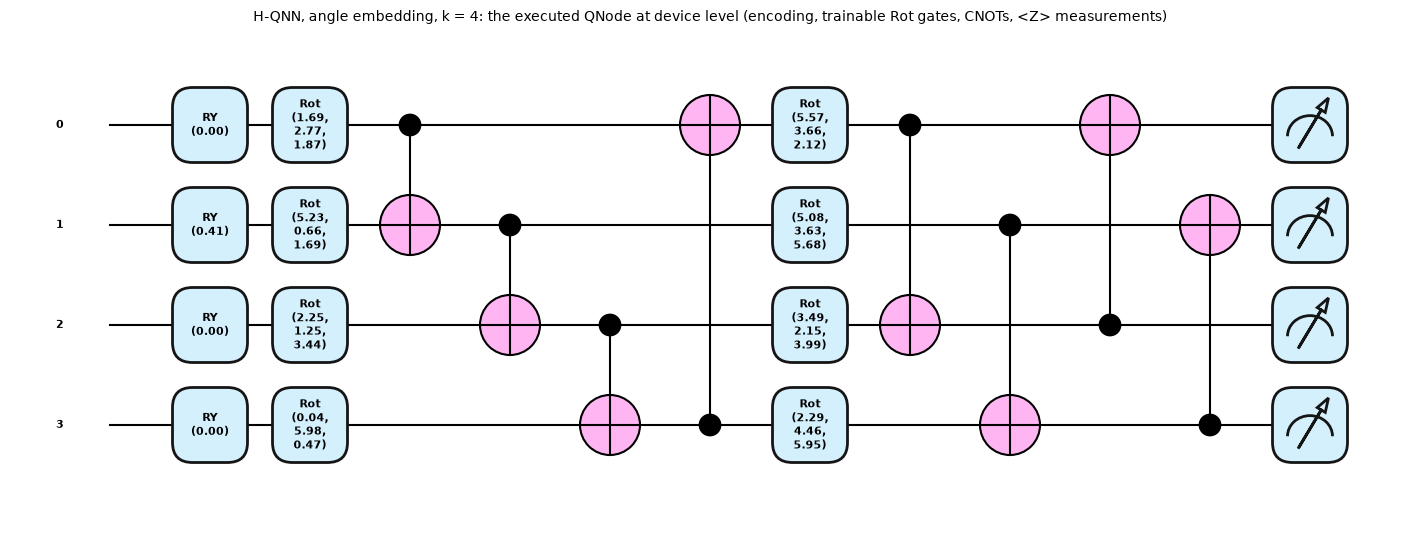

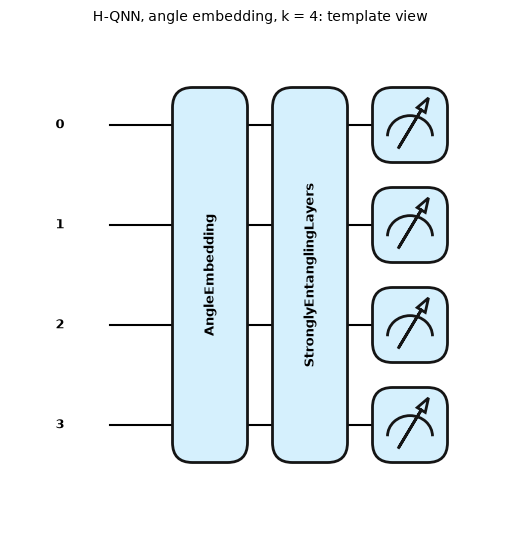

===== amplitude embedding, k = 4 qubits, 24 trainable circuit parameters =====
0: ─╭|Ψ⟩──Rot(1.52,1.00,4.81)─╭●───────╭X──Rot(5.01,5.28,0.86)─╭●────╭X────┤  <Z>
1: ─├|Ψ⟩──Rot(1.87,5.05,2.40)─╰X─╭●────│───Rot(1.46,6.02,2.08)─│──╭●─│──╭X─┤  <Z>
2: ─├|Ψ⟩──Rot(4.94,0.70,1.56)────╰X─╭●─│───Rot(2.03,0.10,1.34)─╰X─│──╰●─│──┤  <Z>
3: ─╰|Ψ⟩──Rot(4.10,3.81,2.34)───────╰X─╰●──Rot(3.93,2.73,0.86)────╰X────╰●─┤  <Z>


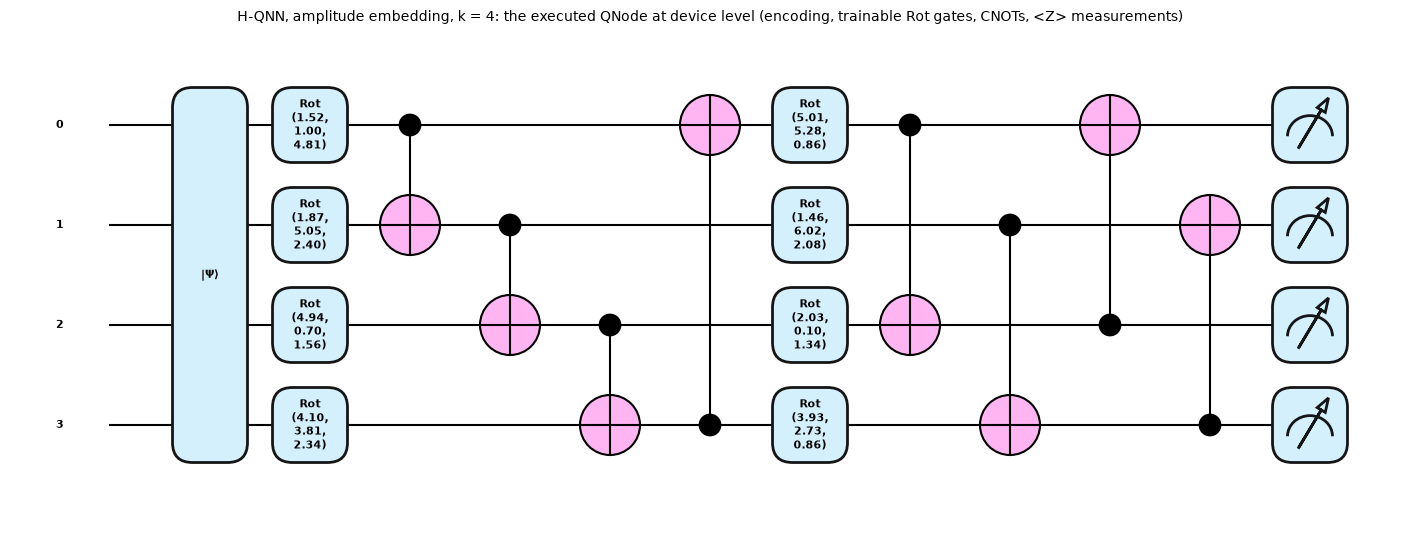

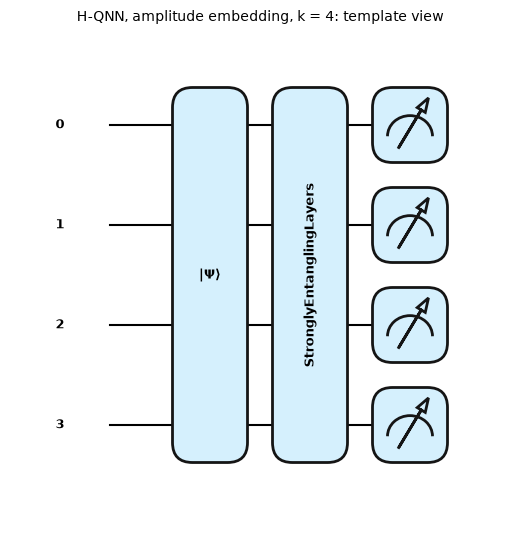

===== iqp embedding, k = 4 qubits, 24 trainable circuit parameters =====
0: ──H──RZ(0.00)─╭MultiRZ(0.00)─╭MultiRZ(0.00)─╭MultiRZ(0.00)──Rot(1.69,2.77,1.87)─────────────────────────────────────╭●──────────────────────── ···
1: ──H──RZ(0.41)─╰MultiRZ(0.00)─│──────────────│──────────────╭MultiRZ(0.00)───────╭MultiRZ(0.00)──Rot(5.23,0.66,1.69)─╰X───────────────────╭●─── ···
2: ──H──RZ(0.00)────────────────╰MultiRZ(0.00)─│──────────────╰MultiRZ(0.00)───────│──────────────╭MultiRZ(0.00)────────Rot(2.25,1.25,3.44)─╰X─╭● ···
3: ──H──RZ(0.00)───────────────────────────────╰MultiRZ(0.00)──────────────────────╰MultiRZ(0.00)─╰MultiRZ(0.00)────────Rot(0.04,5.98,0.47)────╰X ···

0: ··· ─╭X──Rot(5.57,3.66,2.12)─╭●────╭X────┤  <Z>
1: ··· ─│───Rot(5.08,3.63,5.68)─│──╭●─│──╭X─┤  <Z>
2: ··· ─│───Rot(3.49,2.15,3.99)─╰X─│──╰●─│──┤  <Z>
3: ··· ─╰●──Rot(2.29,4.46,5.95)────╰X────╰●─┤  <Z>


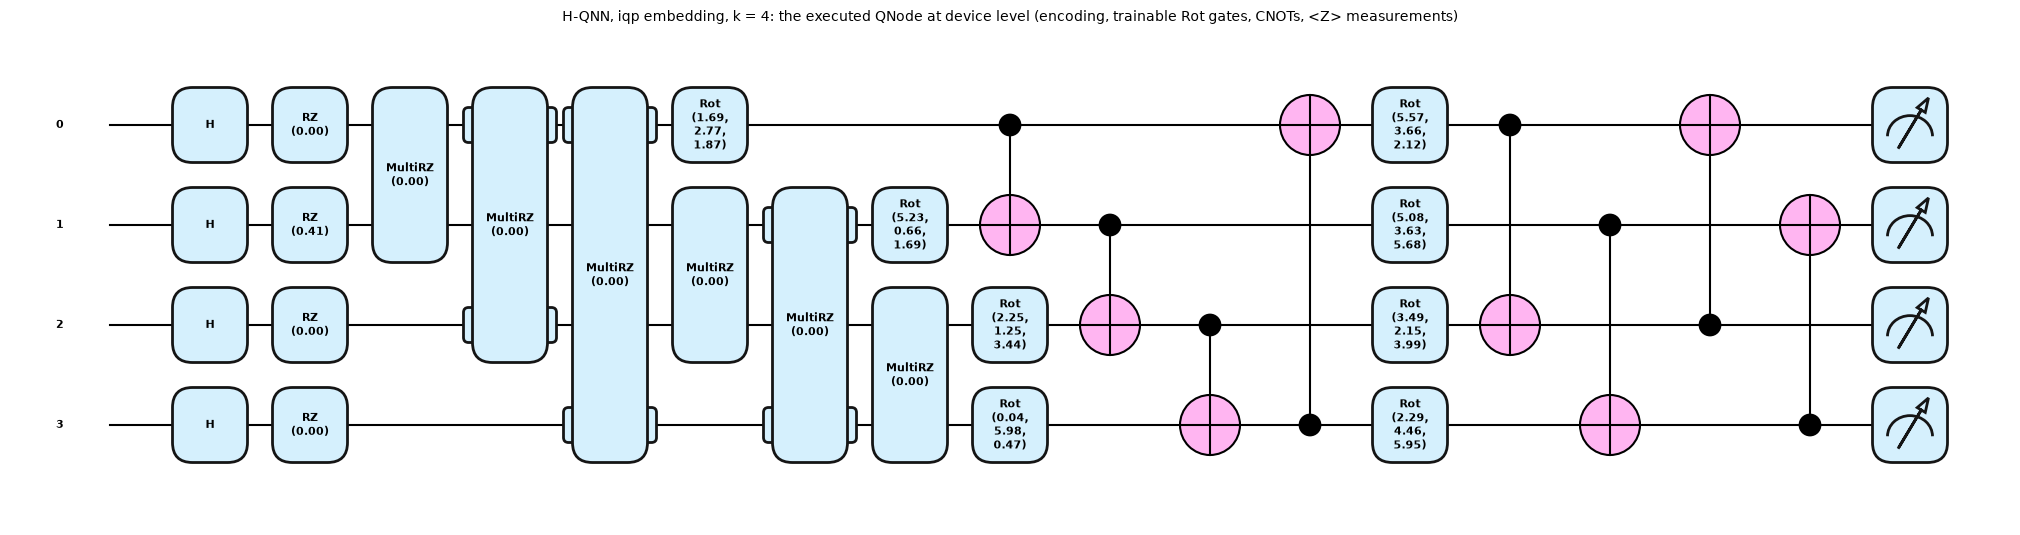

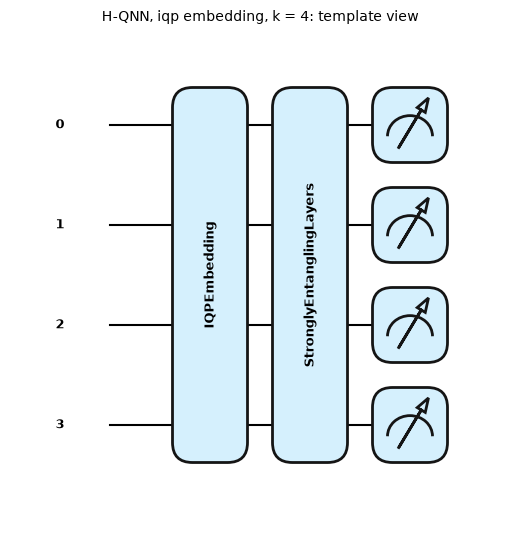

Amplitude embedding is drawn as one state-preparation box (|Psi>) because default.qubit loads the amplitude vector directly; on hardware it compiles into a rotation/CNOT network of depth growing like 2^k.


In [11]:
# Drawings of the executed H-QNN circuits (k = 4 qubits to keep them readable; the structure is identical for other k).
K_DRAW = 4
H_DRAW = {}
for emb in EMBEDDINGS:
    torch.manual_seed(SEED)
    m = HybridQNN(emb, K_DRAW, 1); H_DRAW[emb] = m
    x0 = circuit_input(m, Xb_b[0, :K_DRAW]); w = m.q.qnode_weights["weights"]
    print(f"===== {emb} embedding, k = {K_DRAW} qubits, {m.n_circuit_params()} trainable circuit parameters =====")
    print(qml.draw(m.q.qnode, max_length=150, level="device")(x0, w))
    fig, ax = qml.draw_mpl(m.q.qnode, level="device", decimals=2, style="pennylane", fontsize=8)(x0, w)
    fig.suptitle(f"H-QNN, {emb} embedding, k = {K_DRAW}: the executed QNode at device level (encoding, trainable Rot gates, CNOTs, <Z> measurements)", y=1.03, fontsize=10)
    plt.show()
    fig, ax = qml.draw_mpl(m.q.qnode, decimals=2, style="pennylane", fontsize=9)(x0, w)
    fig.suptitle(f"H-QNN, {emb} embedding, k = {K_DRAW}: template view", y=1.03, fontsize=10)
    plt.show()
print("Amplitude embedding is drawn as one state-preparation box (|Psi>) because default.qubit loads the amplitude vector directly; on hardware it compiles into a rotation/CNOT network of depth growing like 2^k.")

===== QSVM kernel circuit, angle embedding, k = 4 qubits: depth 2, 8 gates, 0 trainable parameters =====
0: ──RY(2.45)──RY(2.71)†─┤ ╭Probs
1: ──RY(0.41)──RY(0.38)†─┤ ├Probs
2: ──RY(0.76)──RY(0.78)†─┤ ├Probs
3: ──RY(0.01)──RY(0.01)†─┤ ╰Probs


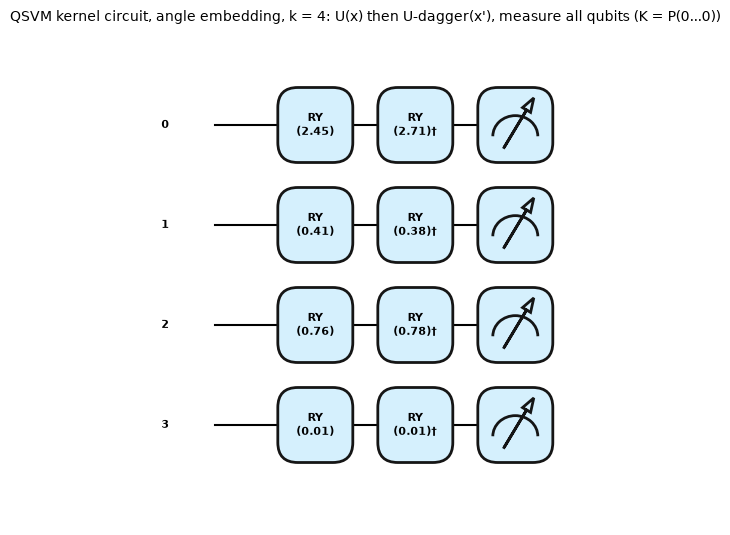

===== QSVM kernel circuit, amplitude embedding, k = 4 qubits: depth 45, 49 gates, 0 trainable parameters =====
0: ─╭|Ψ⟩─╭GlobalPhase(-0.39)†─╭X†───────────────────────────────────╭X†────────────────────────╭X†────────────╭X†─────╭X†─────────────╭X† ···
1: ─├|Ψ⟩─├GlobalPhase(-0.39)†─│──────────────────╭X†────────────────│──────────────────╭X†─────│──────────╭X†─│───╭X†─╰X†──RZ(-0.79)†─╰X† ···
2: ─├|Ψ⟩─├GlobalPhase(-0.39)†─│──────────────╭X†─│───╭X†────────────│──────────────╭X†─│───╭X†─╰X†────────╰X†─╰X†─╰X†──────────────────── ···
3: ─╰|Ψ⟩─╰GlobalPhase(-0.39)†─╰X†──RZ(0.79)†─╰X†─╰X†─╰X†──RZ(0.79)†─╰X†──RZ(0.79)†─╰X†─╰X†─╰X†──RZ(0.79)†──────────────────────────────── ···

0: ··· ──RZ(-0.79)†─╭X†───────────────────────────────────────────────────────────╭X†────────────────────────────────────────────────╭X†─────── ···
1: ··· ──RZ(-0.79)†─│──────────────────────────────╭X†────────────────────────────│──────────────────────────────╭X†─────────────────│───────── ···
2: ··· ─────────────│───

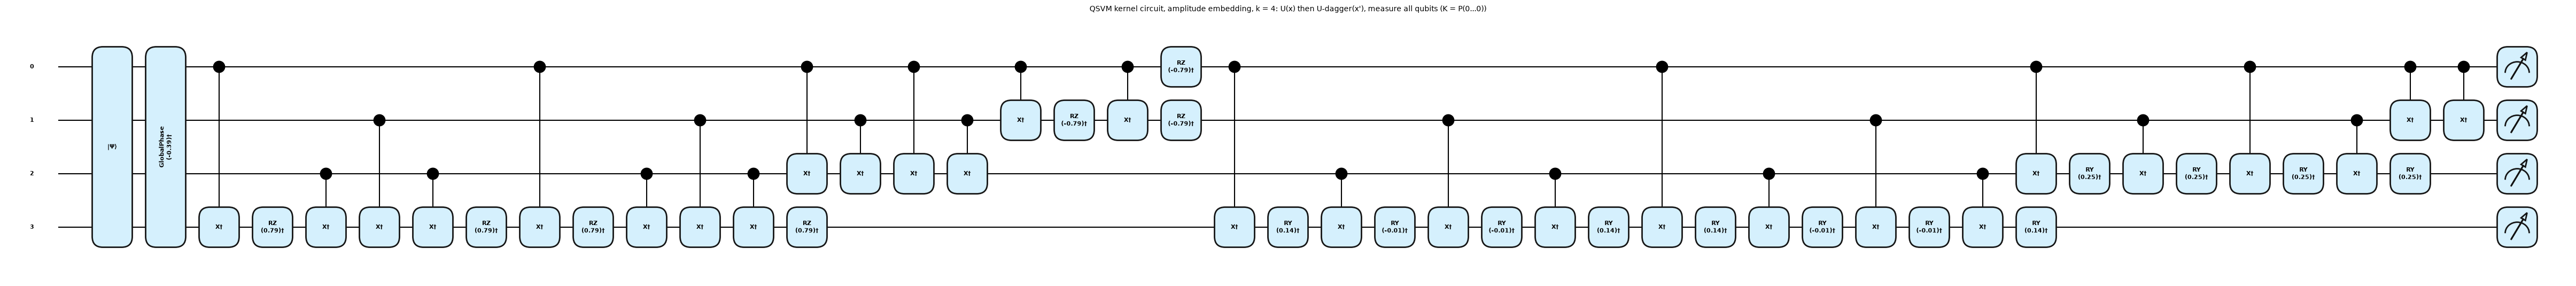

===== QSVM kernel circuit, iqp embedding, k = 4 qubits: depth 14, 28 gates, 0 trainable parameters =====
0: ──H──RZ(2.45)─╭MultiRZ(1.00)─╭MultiRZ(1.86)─╭MultiRZ(0.03)───────────────────────────────────────────────────────────────────────────── ···
1: ──H──RZ(0.41)─╰MultiRZ(1.00)─│──────────────│──────────────╭MultiRZ(0.31)─╭MultiRZ(0.00)────────────────────────────────╭MultiRZ(0.00)† ···
2: ──H──RZ(0.76)────────────────╰MultiRZ(1.86)─│──────────────╰MultiRZ(0.31)─│──────────────╭MultiRZ(0.01)─╭MultiRZ(0.01)†─│────────────── ···
3: ──H──RZ(0.01)───────────────────────────────╰MultiRZ(0.03)────────────────╰MultiRZ(0.00)─╰MultiRZ(0.01)─╰MultiRZ(0.01)†─╰MultiRZ(0.00)† ···

0: ··· ─────────────────╭MultiRZ(0.02)†─╭MultiRZ(2.12)†─╭MultiRZ(1.03)†──RZ(2.71)†──H†─┤ ╭Probs
1: ··· ─╭MultiRZ(0.30)†─│───────────────│───────────────╰MultiRZ(1.03)†──RZ(0.38)†──H†─┤ ├Probs
2: ··· ─╰MultiRZ(0.30)†─│───────────────╰MultiRZ(2.12)†──RZ(0.78)†───────H†────────────┤ ├Probs
3: ··· ─────────────────╰MultiRZ(0

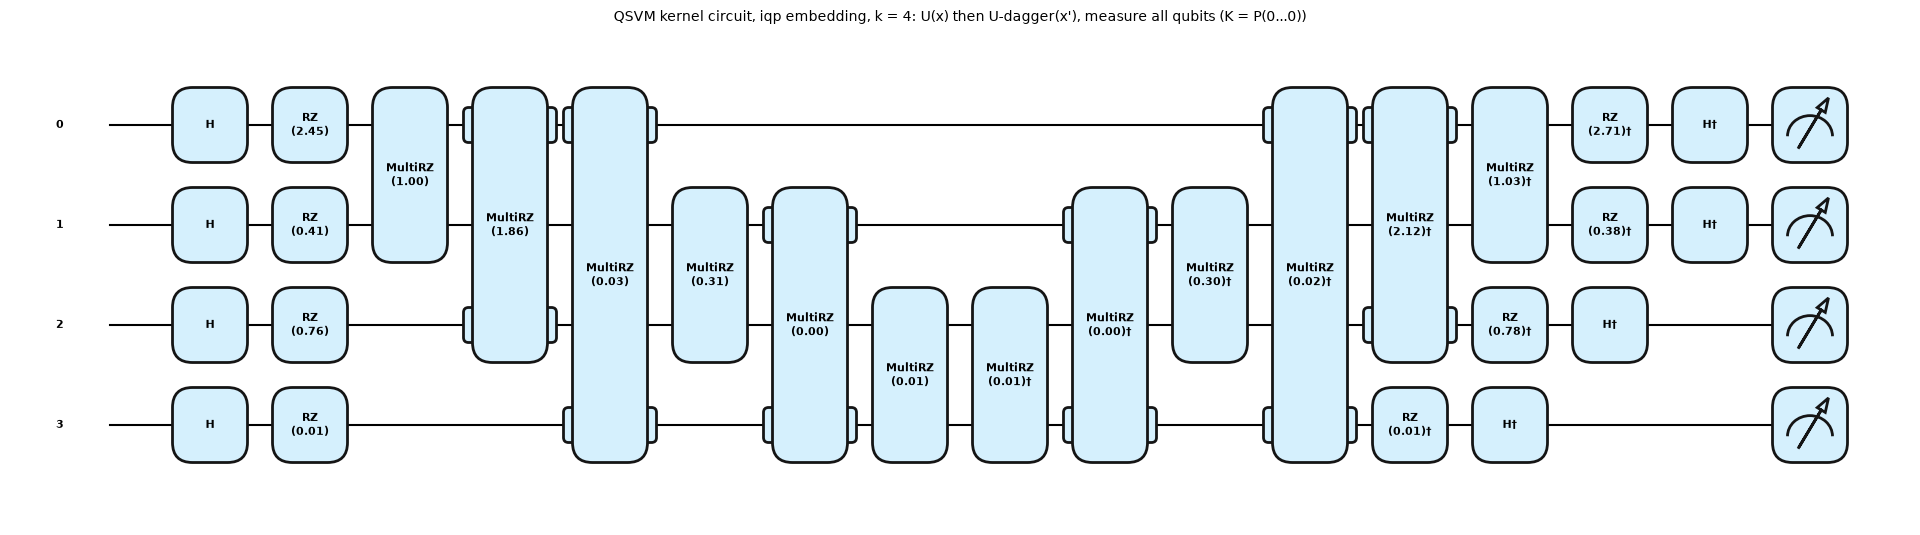

In [12]:
# QSVM kernel circuits: U(x) then adjoint U(x'), probabilities of all qubits; the kernel value is the probability of |0...0>.
def kernel_qnode(emb, k, shots=None):
    dev = qml.device("default.qubit", wires=k)
    @qml.qnode(dev)
    def f(x1, x2):
        embed(emb, x1, range(k)); qml.adjoint(embed)(emb, x2, range(k))
        return qml.probs(wires=range(k))
    return qml.set_shots(f, shots=shots) if shots else f

def state_fn(emb, k):
    dev = qml.device("default.qubit", wires=k)
    @qml.qnode(dev)
    def f(x):
        embed(emb, x, range(k)); return qml.state()
    return f

def states(emb, k, X, chunk=400):
    f = state_fn(emb, k)                                   # parameter broadcasting: one simulator call per chunk of rows
    return np.vstack([np.asarray(f(X[i:i + chunk])) for i in range(0, len(X), chunk)])

def fidelity_kernel(A, B):
    return np.abs(A.conj() @ B.T) ** 2                     # |<phi(a)|phi(b)>|^2 from two sets of state vectors

def qsvm_inputs(Xtr, Xte, emb, k, raw_angles=False):
    """The k numbers per connection that the QSVM embedding receives."""
    Ptr, Pte = Xtr[:, :k], Xte[:, :k]
    if emb == "amplitude" or raw_angles: return Ptr, Pte                       # amplitude: raw scores (normalised by the circuit)
    sc = MinMaxScaler((0.0, np.pi)).fit(Ptr)                                   # CHOICE: angles in [0, pi], fitted on the training rows, test clipped
    return sc.transform(Ptr), np.clip(sc.transform(Pte), 0.0, np.pi)

Xq, yq, _ = balanced(d_b, QSVM_N)
for emb in EMBEDDINGS:
    a_tr, a_te = qsvm_inputs(Xq, d_b["Pte"], emb, K_DRAW)
    kq = kernel_qnode(emb, K_DRAW)
    sp = qml.specs(kq, level="device")(a_tr[0], a_tr[1])["resources"]
    print(f"===== QSVM kernel circuit, {emb} embedding, k = {K_DRAW} qubits: depth {sp.depth}, {sp.num_gates} gates, 0 trainable parameters =====")
    print(qml.draw(kq, max_length=150, level="device")(a_tr[0], a_tr[1]))
    fig, ax = qml.draw_mpl(kq, level="device", decimals=2, style="pennylane", fontsize=8)(a_tr[0], a_tr[1])
    fig.suptitle(f"QSVM kernel circuit, {emb} embedding, k = {K_DRAW}: U(x) then U-dagger(x'), measure all qubits (K = P(0...0))", y=1.03, fontsize=10)
    plt.show()

## 4. The QSVM

The fidelity kernel of the paper (Eq. 14-15) is `K(x, x') = |<phi(x)|phi(x')>|^2 = |<0|U^dagger(x') U(x)|0>|^2`. Evaluating it as the paper describes (one circuit per pair, 1,000 x 1,000 pairs, 1,024 shots)
costs about 10^6 simulator calls per kernel matrix and is what makes the paper's QSVM take ~10 hours. On a simulator the same number is obtained exactly from the two state vectors, so we compute the state vectors
once (PennyLane `qml.state()` with parameter broadcasting) and form `|A^* B^T|^2`. Before using it, the cell below **asserts that this closed form equals the paper's adjoint circuit** on real data
for every embedding, and that a 1,024-shot estimate of the circuit scatters around the exact value as binomial statistics predict. The effect of finite shots on the final accuracy is then emulated by sampling
`Binomial(1024, K)/1024` for every kernel entry (mathematically what 1,024 shots of the all-zero probability give).

`C` is selected by 5-fold cross-validation on the training kernel; the test accuracy for every `C` is printed too (the best of them, "oracle C", is optimistic because it looks at the test rows, which is what the released code does).
Training uses 1,000 class-balanced rows; testing uses the full natural test split of the task.

In [13]:
# --- equivalence of the closed form and the paper's adjoint circuit (real data, every embedding), and the shot-noise check ---
rg_chk = np.random.default_rng(SEED)
for emb in EMBEDDINGS:
    k = 4
    a_tr, _ = qsvm_inputs(Xq, d_b["Pte"], emb, k)
    A = states(emb, k, a_tr[:40]); Kexact = fidelity_kernel(A, A)
    kq = kernel_qnode(emb, k)
    pairs = [(int(i), int(j)) for i, j in rg_chk.integers(0, 40, size=(8, 2))]
    circ = np.array([float(kq(a_tr[i], a_tr[j])[0]) for i, j in pairs]); closed = np.array([Kexact[i, j] for i, j in pairs])
    assert np.allclose(circ, closed, atol=1e-9), (emb, circ, closed)
    ks = kernel_qnode(emb, k, shots=SHOTS)
    est = np.array([float(ks(a_tr[i], a_tr[j])[0]) for i, j in pairs])
    expected_sd = np.sqrt(closed * (1 - closed) / SHOTS).mean()
    print(f"{emb:9s} k={k}: closed form == adjoint circuit on {len(pairs)} real pairs (max diff {np.abs(circ - closed).max():.1e}); "
          f"{SHOTS}-shot estimate: mean |error| {np.abs(est - closed).mean():.4f} (binomial sd {expected_sd:.4f})")
print("diagonal of the kernel is 1 (K(x, x) = |<0|U^dagger(x) U(x)|0>|^2):", np.allclose(np.diag(Kexact), 1.0))

angle     k=4: closed form == adjoint circuit on 8 real pairs (max diff 2.2e-16); 1024-shot estimate: mean |error| 0.0066 (binomial sd 0.0082)


amplitude k=4: closed form == adjoint circuit on 8 real pairs (max diff 1.1e-15); 1024-shot estimate: mean |error| 0.0120 (binomial sd 0.0117)


iqp       k=4: closed form == adjoint circuit on 8 real pairs (max diff 4.4e-16); 1024-shot estimate: mean |error| 0.0055 (binomial sd 0.0070)
diagonal of the kernel is 1 (K(x, x) = |<0|U^dagger(x) U(x)|0>|^2): True


In [14]:
def run_qsvm(task, seed, emb, k, shots=None, raw_angles=False, tag="qsvm"):
    d = get_data(task, seed); Xq, yq, _ = balanced(d, QSVM_N)
    a_tr, a_te = qsvm_inputs(Xq, d["Pte"], emb, k, raw_angles)
    t0 = time.time()
    A, B = states(emb, k, a_tr), states(emb, k, a_te)
    Ktr, Kte = fidelity_kernel(A, A), fidelity_kernel(B, A)
    if shots:                                                                       # emulate the finite-shot kernel estimate
        rs = np.random.default_rng(seed + k)
        U = np.triu(rs.binomial(shots, np.clip(Ktr, 0, 1)) / shots, 1); Ktr = U + U.T + np.eye(len(Ktr))
        Kte = rs.binomial(shots, np.clip(Kte, 0, 1)) / shots
    t_kernel = time.time() - t0
    t1 = time.time()
    gs = GridSearchCV(SVC(kernel="precomputed"), {"C": C_GRID}, cv=StratifiedKFold(5, shuffle=True, random_state=seed)).fit(Ktr, yq)
    yp = gs.predict(Kte); t_fit = time.time() - t1
    per_c = {C: accuracy_score(d["yte"], SVC(kernel="precomputed", C=C).fit(Ktr, yq).predict(Kte)) for C in C_GRID}
    log(task, seed, "QSVM", emb, k, d["yte"], yp, t_kernel + t_fit, tag=tag, best_C=gs.best_params_["C"],
        oracle_acc=max(per_c.values()), acc_by_C=per_c, train_rows=len(yq))
    return yp

t0 = time.time()
for task in ("binary", "multi"):
    for s in SEEDS:
        for emb in EMBEDDINGS:
            for k in QSVM_K:
                run_qsvm(task, s, emb, k)
print("QSVM grid done in %.1f s" % (time.time() - t0))
qs = pd.DataFrame([r for r in ROWS if r["family"] == "QSVM" and r["tag"] == "qsvm" and r["seed"] == SEEDS[0]])
for task in ("binary", "multi"):
    print(f"\nQSVM test accuracy ({task}, seed {SEEDS[0]}, C by CV on the training kernel); oracle = best C on the test rows")
    t = qs[qs.task == task]
    display(t.pivot_table(index="emb", columns="k", values="accuracy").round(4))
    print("oracle C (best C chosen on the test rows, optimistic):"); display(t.pivot_table(index="emb", columns="k", values="oracle_acc").round(4))

QSVM grid done in 125.5 s

QSVM test accuracy (binary, seed 42, C by CV on the training kernel); oracle = best C on the test rows


k,2,4,6,8
emb,,,,
amplitude,0.8458,0.8865,0.9397,0.9557
angle,0.9327,0.9544,0.9607,0.9661
iqp,0.9371,0.9508,0.9752,0.9780


oracle C (best C chosen on the test rows, optimistic):


k,2,4,6,8
emb,,,,
amplitude,0.8458,0.8871,0.9397,0.9557
angle,0.9329,0.9544,0.9607,0.9661
iqp,0.9371,0.9551,0.9752,0.9780



QSVM test accuracy (multi, seed 42, C by CV on the training kernel); oracle = best C on the test rows


k,2,4,6,8
emb,,,,
amplitude,0.7230,0.8180,0.8853,0.9428
angle,0.7142,0.8988,0.9399,0.9528
iqp,0.7817,0.9228,0.9581,0.9514


oracle C (best C chosen on the test rows, optimistic):


k,2,4,6,8
emb,,,,
amplitude,0.7376,0.8232,0.8853,0.9428
angle,0.7218,0.8988,0.9399,0.9528
iqp,0.7896,0.9323,0.9581,0.9514


## 5. Training the hybrid QNNs

Adam on the cross-entropy loss (binary: one logit with the sigmoid cross-entropy of the released code, multiclass: five logits), mini-batches of 64, a fixed budget of `QNN_EPOCHS` epochs on `QNN_CAP`
class-balanced training rows. The released code trains on ~20,000 rows for 20 epochs (hours per model on a GPU-less machine, 3,000-5,000 s in the paper's Table 4/5 for the large PCA sizes);
that is out of reach for an interactive notebook, so the H-QNN numbers below are for a much smaller training budget and are best read as lower bounds. After every epoch the accuracy on the first
500 *training* rows is logged for the convergence curve; the test rows are touched once at the end.

In [15]:
def train_qnn(task, seed, emb, k, L=LAYERS, quantum=True, cap=None, epochs=None, tag="qnn", label=""):
    cap = cap or QNN_CAP; epochs = epochs or QNN_EPOCHS
    d = get_data(task, seed); Xb, yb, _ = balanced(d, cap)
    n_out = 1 if task == "binary" else 5
    torch.manual_seed(seed)
    model = HybridQNN(emb, k, n_out, L, quantum)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    Xt = torch.tensor(Xb[:, :k], dtype=torch.float32)
    Yt = torch.tensor(yb, dtype=torch.float32 if task == "binary" else torch.long)
    loss_fn = torch.nn.BCEWithLogitsLoss() if task == "binary" else torch.nn.CrossEntropyLoss()
    g = torch.Generator().manual_seed(seed)
    predict = (lambda lo: (lo.squeeze(1) > 0).long()) if task == "binary" else (lambda lo: lo.argmax(1))
    def run(X):
        out = []
        with torch.no_grad():
            for i in range(0, len(X), 1024): out.append(predict(model(torch.as_tensor(X[i:i + 1024], dtype=torch.float32))))
        return torch.cat(out).numpy()
    hist = []; t0 = time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(Xt), generator=g); tot = 0.0
        for i in range(0, len(Xt), BATCH):
            idx = perm[i:i + BATCH]
            if len(idx) < 2: continue
            lo = model(Xt[idx]); loss = loss_fn(lo.squeeze(1) if task == "binary" else lo, Yt[idx])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        acc = float((run(Xb[:PROBE, :k]) == yb[:PROBE]).mean()); hist.append((tot / len(Xt), acc))
    train_s = time.time() - t0
    t1 = time.time(); yp = run(d["Pte"][:, :k]); pred_s = time.time() - t1
    name = "H-QNN" if quantum else "classical twin"
    log(task, seed, name, emb, k, d["yte"], yp, train_s + pred_s, tag=tag, layers=L, circuit_params=model.n_circuit_params(),
        total_params=model.n_params(), hist=hist, train_rows=len(yb), epochs=epochs)
    print(f"  {task:6s} {name:14s} {emb:9s} k={k:2d} L={L} seed {seed}: acc {ROWS[-1]['accuracy']:.4f} F1 {ROWS[-1]['f1']:.4f} "
          f"loss {hist[0][0]:.3f}->{hist[-1][0]:.3f}  {train_s + pred_s:.0f} s", flush=True)
    return model

t_all = time.time(); MODELS = {}
for task in ("binary", "multi"):
    for emb in EMBEDDINGS:
        for k in QNN_K:
            MODELS[(task, emb, k)] = train_qnn(task, SEED, emb, k)
for (task, emb, k) in QNN_EXTRA_CFG:                      # FAST_MODE only: the three PCA-10 H-QNNs of Tables 4 and 5
    MODELS[(task, emb, k)] = train_qnn(task, SEED, emb, k)
print("main H-QNN grid: %.1f min" % ((time.time() - t_all) / 60))

  binary H-QNN          angle     k= 2 L=2 seed 42: acc 0.9248 F1 0.9244 loss 0.604->0.254  6 s


  binary H-QNN          angle     k= 4 L=2 seed 42: acc 0.9375 F1 0.9375 loss 0.622->0.210  12 s


  binary H-QNN          angle     k= 6 L=2 seed 42: acc 0.9575 F1 0.9575 loss 0.574->0.146  22 s


  binary H-QNN          angle     k= 8 L=2 seed 42: acc 0.9559 F1 0.9559 loss 0.641->0.155  40 s


  binary H-QNN          amplitude k= 2 L=2 seed 42: acc 0.8970 F1 0.8955 loss 0.535->0.294  7 s


...

  multi  H-QNN          iqp       k= 8 L=2 seed 42: acc 0.8438 F1 0.8798 loss 1.550->0.765  82 s


  binary H-QNN          angle     k=10 L=2 seed 42: acc 0.9597 F1 0.9597 loss 0.555->0.138  169 s


  binary H-QNN          amplitude k=10 L=2 seed 42: acc 0.9675 F1 0.9675 loss 0.486->0.096  82 s


  multi  H-QNN          amplitude k=10 L=2 seed 42: acc 0.9204 F1 0.9361 loss 1.335->0.247  95 s


main H-QNN grid: 15.0 min


## 6. Results: tables, convergence and confusion matrices

In [16]:
R = pd.DataFrame(ROWS)
main = R[(R.seed == SEED) & (R.tag.isin(["cap", "qnn", "qsvm"]))].copy()
main["model"] = main.family + np.where(main.emb.isin(["angle", "amplitude", "iqp"]), " (" + main.emb + ")", "")
for task in ("binary", "multi"):
    print(f"\n===== {task}: test accuracy by model and PCA size (seed {SEED}; H-QNN budget: {QNN_CAP} rows, {QNN_EPOCHS} epochs; QSVM: {QSVM_N} rows) =====")
    t = main[main.task == task].pivot_table(index="model", columns="k", values="accuracy")
    display(t.round(4))
    print(f"weighted F1:")
    display(main[main.task == task].pivot_table(index="model", columns="k", values="f1").round(4))


===== binary: test accuracy by model and PCA size (seed 42; H-QNN budget: 1500 rows, 3 epochs; QSVM: 1000 rows) =====


k,2,4,6,8,10
model,,,,,
H-QNN (amplitude),0.8970,0.9022,0.9496,0.9655,0.9675
H-QNN (angle),0.9248,0.9375,0.9575,0.9559,0.9597
H-QNN (iqp),0.8873,0.9276,0.9438,0.9490,NaN
Logistic Regression,0.8835,0.9049,0.9361,0.9426,0.9476
MLP (64-32),0.9307,0.9621,0.9786,0.9806,0.9843
QSVM (amplitude),0.8458,0.8865,0.9397,0.9557,NaN
QSVM (angle),0.9327,0.9544,0.9607,0.9661,NaN
QSVM (iqp),0.9371,0.9508,0.9752,0.9780,NaN
Random Forest,0.9378,0.9770,0.9784,0.9797,0.9825


weighted F1:


k,2,4,6,8,10
model,,,,,
H-QNN (amplitude),0.8955,0.9016,0.9496,0.9655,0.9675
H-QNN (angle),0.9244,0.9375,0.9575,0.9559,0.9597
H-QNN (iqp),0.8871,0.9275,0.9438,0.9490,NaN
Logistic Regression,0.8825,0.9047,0.9361,0.9426,0.9476
MLP (64-32),0.9306,0.9621,0.9786,0.9806,0.9843
QSVM (amplitude),0.8456,0.8865,0.9396,0.9558,NaN
QSVM (angle),0.9322,0.9542,0.9606,0.9660,NaN
QSVM (iqp),0.9367,0.9506,0.9752,0.9780,NaN
Random Forest,0.9377,0.9770,0.9784,0.9797,0.9825



===== multi: test accuracy by model and PCA size (seed 42; H-QNN budget: 1500 rows, 3 epochs; QSVM: 1000 rows) =====


k,2,4,6,8,10
model,,,,,
H-QNN (amplitude),0.8085,0.4693,0.8851,0.9149,0.9204
H-QNN (angle),0.7827,0.6930,0.8333,0.8623,NaN
H-QNN (iqp),0.7434,0.7384,0.8605,0.8438,NaN
Logistic Regression,0.6847,0.8327,0.8758,0.9055,0.9008
MLP (64-32),0.8337,0.9260,0.9530,0.9460,0.9563
QSVM (amplitude),0.7230,0.8180,0.8853,0.9428,NaN
QSVM (angle),0.7142,0.8988,0.9399,0.9528,NaN
QSVM (iqp),0.7817,0.9228,0.9581,0.9514,NaN
Random Forest,0.8600,0.9401,0.9513,0.9549,0.9631


weighted F1:


k,2,4,6,8,10
model,,,,,
H-QNN (amplitude),0.8194,0.5197,0.9050,0.9293,0.9361
H-QNN (angle),0.8132,0.7447,0.8650,0.8851,NaN
H-QNN (iqp),0.7942,0.7718,0.9003,0.8798,NaN
Logistic Regression,0.7537,0.8594,0.8952,0.9193,0.9226
MLP (64-32),0.8774,0.9369,0.9607,0.9579,0.9639
QSVM (amplitude),0.7796,0.8430,0.8973,0.9501,NaN
QSVM (angle),0.7907,0.9197,0.9480,0.9594,NaN
QSVM (iqp),0.8510,0.9328,0.9623,0.9595,NaN
Random Forest,0.8943,0.9495,0.9596,0.9628,0.9687


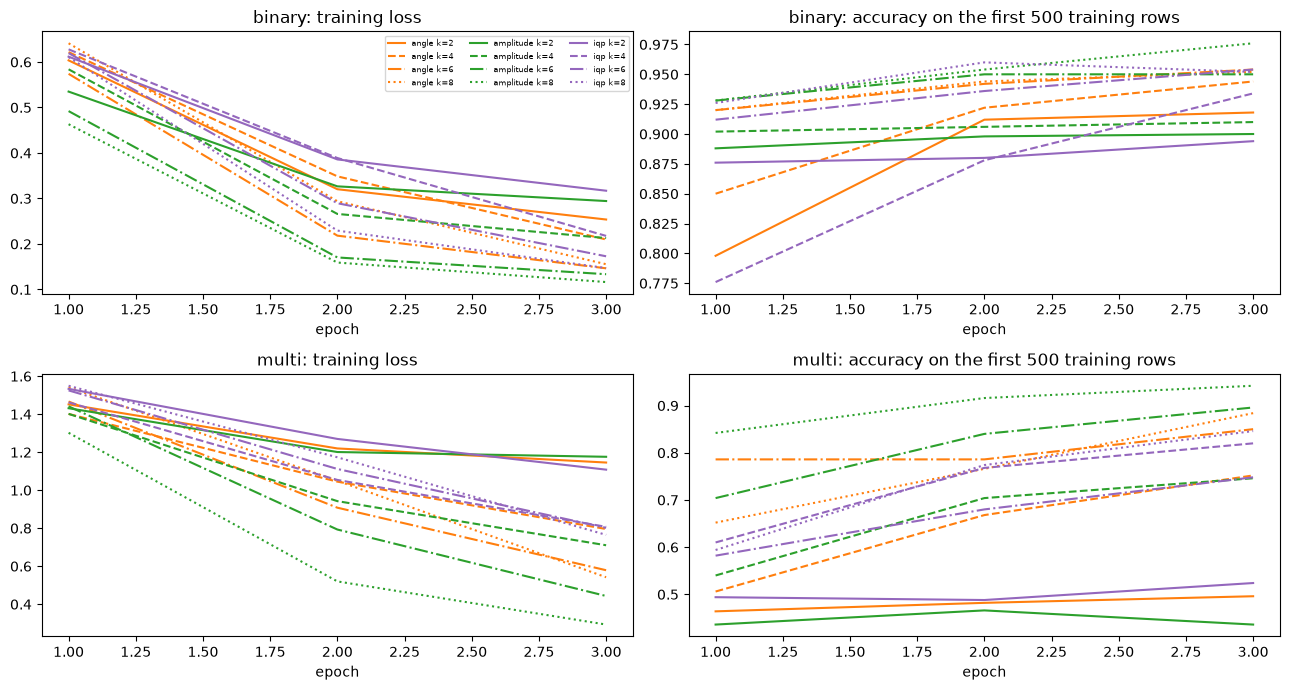

In [17]:
# Convergence of the H-QNN runs (seed SEED), one panel per task
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for r_i, task in enumerate(("binary", "multi")):
    for emb, col in zip(EMBEDDINGS, ["tab:orange", "tab:green", "tab:purple"]):
        for k, ls in zip(QNN_K, ["-", "--", "-.", ":", (0, (1, 3))][:len(QNN_K)]):
            h = next(r["hist"] for r in ROWS if r["family"] == "H-QNN" and r["task"] == task and r["emb"] == emb and r["k"] == k and r["tag"] == "qnn" and r["seed"] == SEED)
            axes[r_i, 0].plot(range(1, len(h) + 1), [x[0] for x in h], color=col, ls=ls, label=f"{emb} k={k}")
            axes[r_i, 1].plot(range(1, len(h) + 1), [x[1] for x in h], color=col, ls=ls)
    axes[r_i, 0].set_title(f"{task}: training loss"); axes[r_i, 1].set_title(f"{task}: accuracy on the first {PROBE} training rows")
    axes[r_i, 0].set_xlabel("epoch"); axes[r_i, 1].set_xlabel("epoch")
axes[0, 0].legend(fontsize=6, ncol=3)
plt.tight_layout(); plt.show()

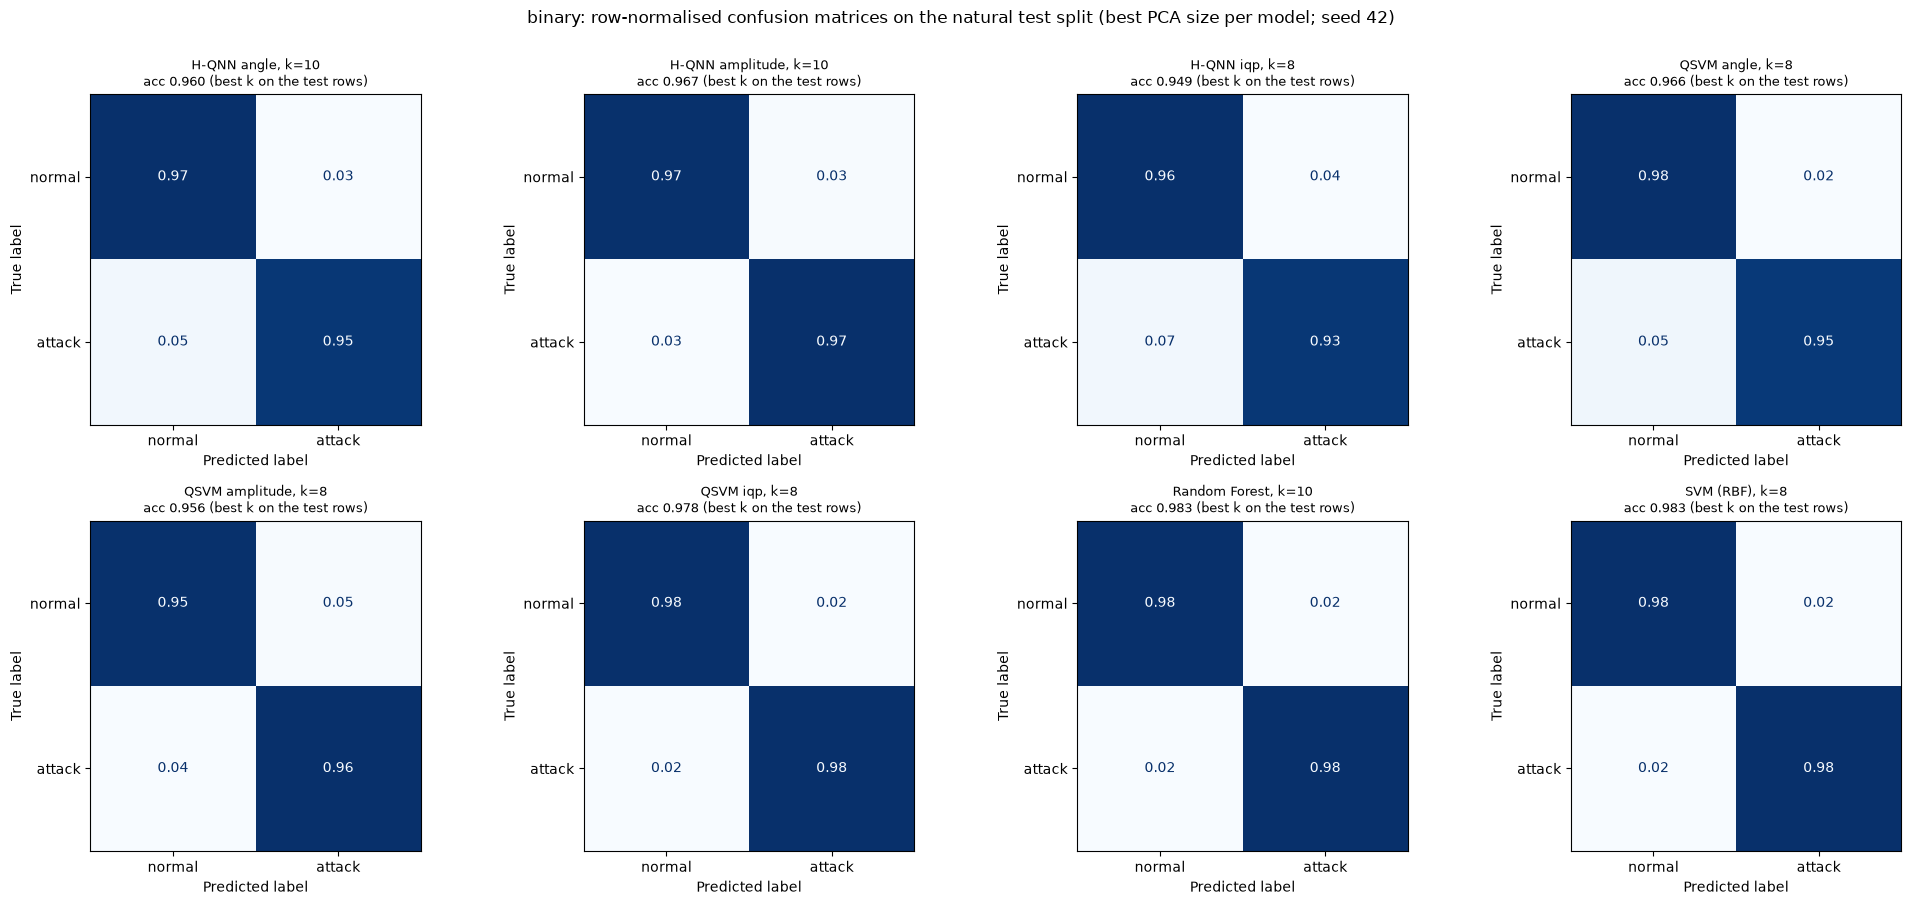

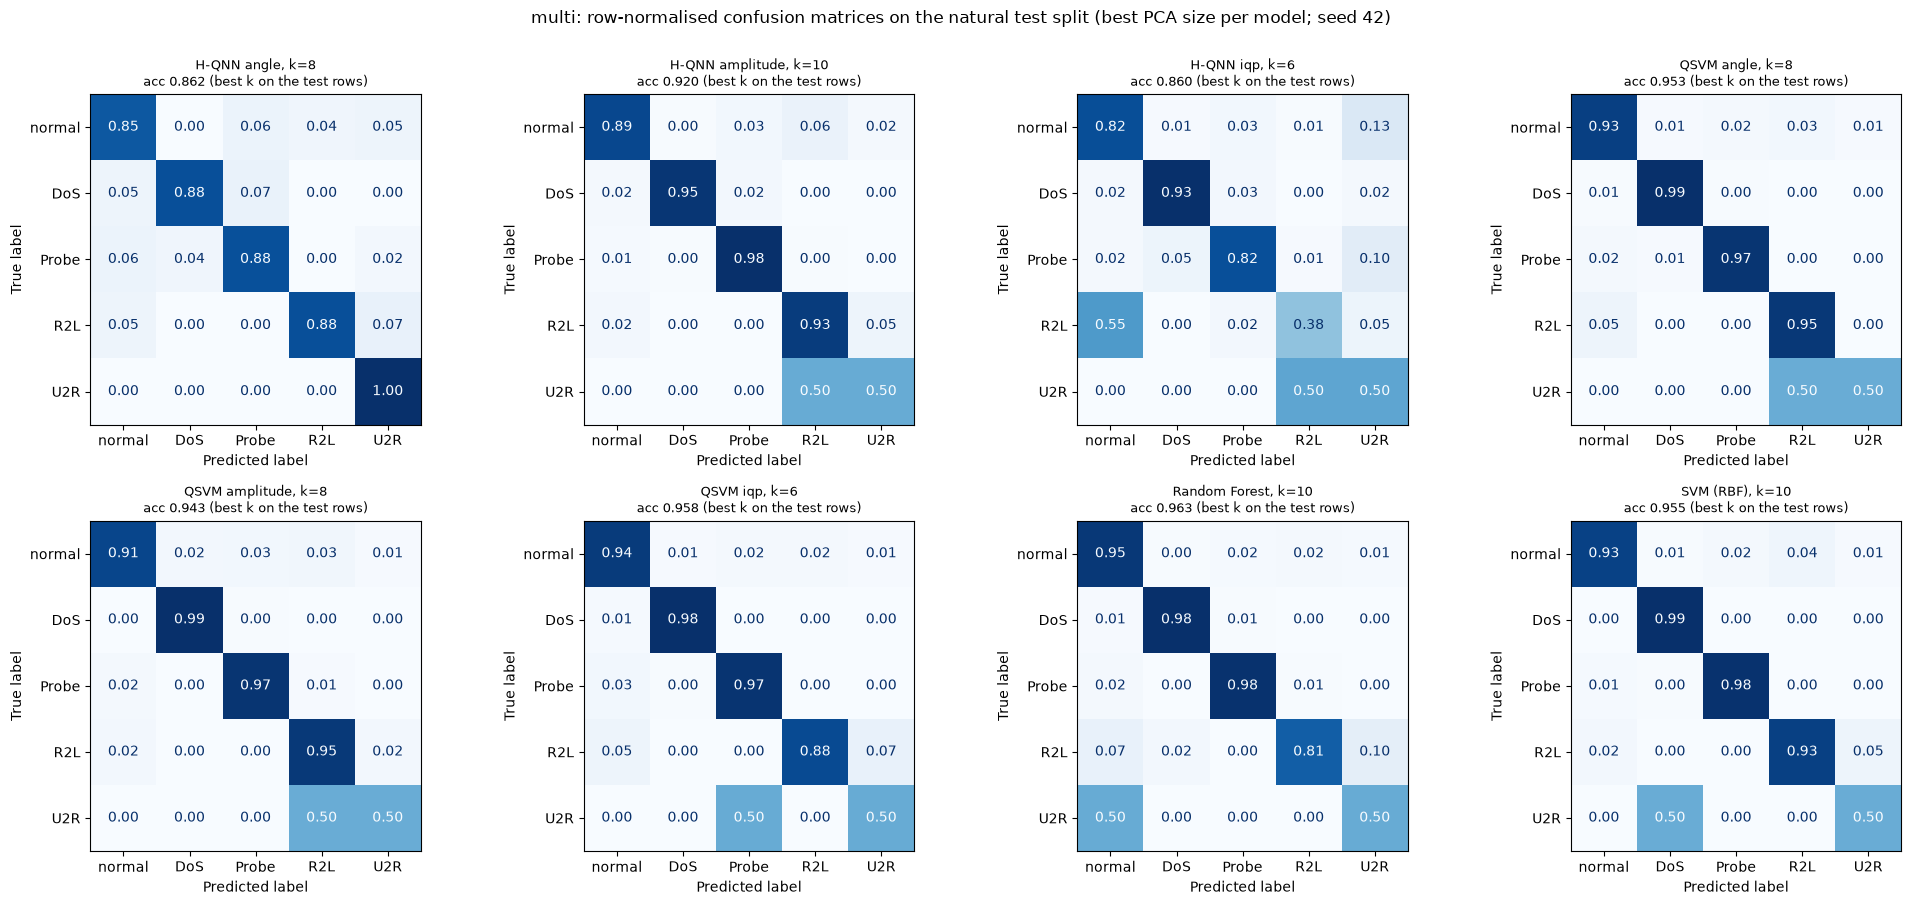

In [18]:
# Confusion matrices in the style of the paper's Figs. 12 (binary) and 13 (multiclass), row-normalised, attack/normal as in the data
def best_row(task, family, emb=None, tags=("cap", "qnn", "qsvm"), key="accuracy"):
    t = R[(R.task == task) & (R.seed == SEED) & (R.family == family) & (R.tag.isin(tags))]
    if emb is not None: t = t[t.emb == emb]
    return t.sort_values(key, ascending=False).iloc[0]

for task in ("binary", "multi"):
    picks = [("H-QNN", e) for e in EMBEDDINGS] + [("QSVM", e) for e in EMBEDDINGS] + [("Random Forest", None), ("SVM (RBF)", None)]
    fig, axes = plt.subplots(2, 4, figsize=(20, 9)); axes = axes.ravel()
    d = get_data(task, SEED); labs = list(range(len(d["classes"])))
    for ax, (fam, emb) in zip(axes, picks):
        r = best_row(task, fam, emb)
        yp = PRED[(task, SEED, r.family, r.emb, r.k, r.tag)]
        cm = confusion_matrix(d["yte"], yp, labels=labs, normalize="true")
        ConfusionMatrixDisplay(cm, display_labels=d["classes"]).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
        ax.set_title(f"{fam}{' ' + emb if emb else ''}, k={r.k}\nacc {r.accuracy:.3f} (best k on the test rows)", fontsize=9)
    for ax in axes[len(picks):]: ax.axis("off")
    fig.suptitle(f"{task}: row-normalised confusion matrices on the natural test split (best PCA size per model; seed {SEED})", y=1.0)
    plt.tight_layout(); plt.show()

## 7. Controls and audits

1. **Classical twin of the H-QNN.** The same network with the quantum circuit replaced by `Linear + tanh` (same k inputs and k outputs): does the circuit add anything?
2. **Released circuit depth.** `StronglyEntanglingLayers` with 6 layers (the code) against 2 layers (the paper's Table 2).
3. **Seed spread.** The angle H-QNN with k = 4 on other seeds (new split, new balanced sample, new initialisation).
4. **QSVM finite shots and angle scale.** 1,024-shot kernel estimates against the exact kernel, and the released code's raw (unscaled) PCA angles against angles scaled to [0, pi].
5. **Evaluation-order audit.** The released notebooks standardise, SMOTE and PCA *all* rows and only then split. We repeat Random Forest and SVM (RBF) with that order and compare with our train-only order.

In [19]:
t_ab = time.time()
TW_K = [4] if FAST_MODE else [4, 6]
for task in ("binary", "multi"):
    for k in TW_K:
        train_qnn(task, SEED, "angle", k, quantum=False, tag="twin")
    for k in L6_K:
        train_qnn(task, SEED, "angle", k, L=6, tag="L6")
    for s in EXTRA_QNN_SEEDS:
        train_qnn(task, s, "angle", 4, tag="seed")
print("controls finished in %.1f min" % ((time.time() - t_ab) / 60))
R = pd.DataFrame(ROWS)

# 4. QSVM shots and raw angles
for task in ("binary", "multi"):
    for emb in EMBEDDINGS:
        run_qsvm(task, SEED, emb, 6, shots=SHOTS, tag="shots")
    run_qsvm(task, SEED, "angle", 6, raw_angles=True, tag="rawangle")
    run_qsvm(task, SEED, "iqp", 6, raw_angles=True, tag="rawangle")
R = pd.DataFrame(ROWS)

def cmp(task, tags, cols=("family", "emb", "k", "layers", "seed", "tag", "accuracy", "f1", "time_s")):
    t = R[(R.task == task) & R.tag.isin(tags)]
    return t[[c for c in cols if c in t.columns]]
for task in ("binary", "multi"):
    print(f"\n===== {task} =====")
    ref = R[(R.task == task) & (R.seed == SEED) & (R.tag == "qnn") & (R.emb == "angle") & (R.k.isin(TW_K + L6_K + [4]))]
    print("H-QNN angle (reference rows, L = 2):"); display(ref[["family", "emb", "k", "layers", "tag", "accuracy", "f1", "time_s"]].round(4))
    print("classical twin / released depth L = 6 / other seeds:"); display(cmp(task, ["twin", "L6", "seed"]).round(4))
    q6 = R[(R.task == task) & (R.family == "QSVM") & (R.k == 6) & (R.seed == SEED)]
    print("QSVM k = 6: exact kernel vs 1,024-shot kernel vs raw (unscaled) PCA angles:")
    display(q6[["emb", "tag", "accuracy", "f1", "best_C"]].round(4).sort_values(["emb", "tag"]))

  binary classical twin angle     k= 4 L=2 seed 42: acc 0.9361 F1 0.9361 loss 0.471->0.202  1 s


  binary H-QNN          angle     k= 4 L=6 seed 42: acc 0.9526 F1 0.9524 loss 0.568->0.165  19 s


  binary H-QNN          angle     k= 4 L=2 seed 43: acc 0.9002 F1 0.8992 loss 0.676->0.244  7 s


  multi  classical twin angle     k= 4 L=2 seed 42: acc 0.7658 F1 0.8146 loss 1.301->0.670  2 s


  multi  H-QNN          angle     k= 4 L=6 seed 42: acc 0.7640 F1 0.8116 loss 1.424->0.661  19 s


...

,family,emb,k,layers,tag,accuracy,f1,time_s
95,H-QNN,angle,4,2.0,qnn,0.693,0.7447,10.6242


classical twin / released depth L = 6 / other seeds:


,family,emb,k,layers,seed,tag,accuracy,f1,time_s
112,classical twin,angle,4,2.0,42,twin,0.7658,0.8146,1.7608
113,H-QNN,angle,4,6.0,42,L6,0.7640,0.8116,19.2268
114,H-QNN,angle,4,2.0,43,seed,0.6866,0.7551,7.8071


QSVM k = 6: exact kernel vs 1,024-shot kernel vs raw (unscaled) PCA angles:


,emb,tag,accuracy,f1,best_C
76,amplitude,qsvm,0.8853,0.8973,100.0
121,amplitude,shots,0.8641,0.8805,10.0
72,angle,qsvm,0.9399,0.9480,100.0
123,angle,rawangle,0.9474,0.9557,100.0
120,angle,shots,0.8974,0.9153,10.0
80,iqp,qsvm,0.9581,0.9623,100.0
124,iqp,rawangle,0.9079,0.9303,100.0
122,iqp,shots,0.9452,0.9531,10.0


In [20]:
# 5. Evaluation-order audit: "released order" = StandardScaler -> SMOTE on ALL rows -> PCA on ALL rows -> 80/20 split (what the released notebooks do)
def leaky_order(task, k=10, seed=SEED):
    ycol = "binary" if task == "binary" else "fam_id"
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(raw[CAT_COLS])
    X = np.hstack([raw[NUM_COLS].to_numpy(float), enc.transform(raw[CAT_COLS])]); y = raw[ycol].to_numpy()
    X = StandardScaler().fit_transform(X)
    X, y = SMOTE(random_state=seed).fit_resample(X, y)              # synthetic rows are created from, and then split into, test rows too
    X = PCA(n_components=k, random_state=seed).fit_transform(StandardScaler().fit_transform(X))
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, random_state=seed)
    out = {}
    for name, m in [("Random Forest", RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1)), ("SVM (RBF)", SVC(kernel="rbf"))]:
        t0 = time.time()
        if name == "SVM (RBF)" and len(Xtr) > 12000:                  # keep the audit cheap: subsample the SVM's training rows
            ii = np.random.default_rng(seed).choice(len(Xtr), 12000, replace=False); m.fit(Xtr[ii], ytr[ii])
        else: m.fit(Xtr, ytr)
        out[name] = accuracy_score(yte, m.predict(Xte))
    return out, len(y)

audit = []
for task in ("binary", "multi"):
    leak, n_rows = leaky_order(task)
    for name in ("Random Forest", "SVM (RBF)"):
        clean = R[(R.task == task) & (R.seed == SEED) & (R.family == name) & (R.tag == "cap") & (R.k == 10)]["accuracy"].iloc[0]
        audit.append(dict(task=task, model=name, k=10, released_order_acc=round(leak[name], 4), train_only_order_acc=round(clean, 4),
                          gap=round(leak[name] - clean, 4), rows_after_smote_all=n_rows))
AUDIT = pd.DataFrame(audit); display(AUDIT)
print("released-order accuracy is measured on a test set that contains SMOTE rows interpolated from training neighbours; the train-only order tests on real, untouched connections.")

,task,model,k,released_order_acc,train_only_order_acc,gap,rows_after_smote_all
0,binary,Random Forest,10,0.9939,0.9825,0.0113,26898
1,binary,SVM (RBF),10,0.9822,0.9742,0.0080,26898
2,multi,Random Forest,10,0.9976,0.9631,0.0345,67245
3,multi,SVM (RBF),10,0.9571,0.9546,0.0025,67245


released-order accuracy is measured on a test set that contains SMOTE rows interpolated from training neighbours; the train-only order tests on real, untouched connections.


## 8. Where do the paper's numbers come from? The released CSV files

The repository contains the CSV files that the authors' notebooks wrote (`results/...`). We download them from the pinned commit and compare the best row of each family with Tables 4 and 5.
This does not test the method; it tests whether the published tables are traceable to the released results.

In [21]:
import requests, io
CSV = {
 ("binary", "H-QNN", "angle"):     "results/binary/qnn/results_Binary_qnn_hybrid_AngleEmbedding.csv",
 ("binary", "H-QNN", "amplitude"): "results/binary/qnn/results_Binary_qnn_hybrid_AmplitudeEmbedding.csv",
 ("binary", "H-QNN", "iqp"):       "results/binary/qnn/results_Binary_qnn_hybrid_IQPEmbedding.csv",
 ("binary", "QSVM", "angle"):      "results/binary/qsvm/results_Binary_qsvm_angleEmbedding.csv",
 ("binary", "QSVM", "amplitude"):  "results/binary/qsvm/results_Binary_qsvm_AmplitudeEmbedding.csv",
 ("binary", "QSVM", "iqp"):        "results/binary/qsvm/results_Binary_qsvm_IQPEmbedding.csv",
 ("binary", "SVM (RBF)", "-"):     "results/classical_Models/binary/svm_pca_binary_model_performance.csv",
 ("binary", "Random Forest", "-"): "results/classical_Models/binary/rf_pca_binary_model_performance.csv",
 ("binary", "Logistic Regression", "-"): "results/classical_Models/binary/lr_pca_binary_model_performance.csv",
 ("multi", "H-QNN", "angle"):      "results/Multiclasses/qnn/results_Multiclass_qnn_hybrid_AngleEmbedding.csv",
 ("multi", "H-QNN", "amplitude"):  "results/Multiclasses/qnn/results_Multiclasses_qnn_hybrid_AmplitudeEmbedding.csv",
 ("multi", "H-QNN", "iqp"):        "results/Multiclasses/qnn/results_multiclass_qnn_hybrid_IQPEmbedding.csv",
 ("multi", "QSVM", "angle"):       "results/Multiclasses/qsvm/results_Multiclass_qsvm_angleEmbedding.csv",
 ("multi", "QSVM", "amplitude"):   "results/Multiclasses/qsvm/results_multiclass_qsvm_AmplitudeEmbedding.csv",
 ("multi", "QSVM", "iqp"):         "results/Multiclasses/qsvm/results_Multiclass_qsvm_IQPEmbedding.csv",
 ("multi", "SVM (RBF)", "-"):      "results/classical_Models/multiclasses/Multi_svm_pca_resampled_model_performance.csv",
 ("multi", "Random Forest", "-"):  "results/classical_Models/multiclasses/Multi_rf_pca_resampled_model_performance.csv",
 ("multi", "Logistic Regression", "-"): "results/classical_Models/multiclasses/Multi_lr_pca_resampled_model_performance.csv",
}
REL = []
for (task, fam, emb), path in CSV.items():
    try:
        r = requests.get(REPO_RAW + path.replace(" ", "%20"), timeout=60); r.raise_for_status()
        df = pd.read_csv(io.StringIO(r.text))
        acc_col = "Accuracy"; kcol = "PCA_components" if "PCA_components" in df.columns else "Components"
        b = df.sort_values(acc_col, ascending=False).iloc[0]
        f1c = "F1_Score" if "F1_Score" in df.columns else ("F1-score (Weighted Avg)" if "F1-score (Weighted Avg)" in df.columns else None)
        REL.append(dict(task=task, family=fam, emb=emb, released_best_acc=round(float(b[acc_col]), 4), at_k=int(b[kcol]),
                        released_f1=round(float(b[f1c]), 4) if f1c else np.nan, n_rows_in_csv=len(df)))
    except Exception as e:
        REL.append(dict(task=task, family=fam, emb=emb, released_best_acc=np.nan, at_k=-1, released_f1=np.nan, n_rows_in_csv=0))
        print("could not fetch", path, type(e).__name__)
REL = pd.DataFrame(REL)
print("Best accuracy in the authors' own released CSV files (the QSVM CSVs report accuracies on 60-200 test rows):")
display(REL)

Best accuracy in the authors' own released CSV files (the QSVM CSVs report accuracies on 60-200 test rows):


,task,family,emb,released_best_acc,at_k,released_f1,n_rows_in_csv
0,binary,H-QNN,angle,0.9929,10,0.9929,5
1,binary,H-QNN,amplitude,0.9764,10,0.9764,5
2,binary,H-QNN,iqp,0.9766,6,0.9766,5
3,binary,QSVM,angle,0.9750,8,NaN,20
4,binary,QSVM,amplitude,0.9550,2,NaN,20
5,binary,QSVM,iqp,1.0000,2,NaN,20
6,binary,SVM (RBF),-,0.9940,8,0.9940,5
7,binary,Random Forest,-,0.9972,10,0.9972,5
8,binary,Logistic Regression,-,0.9734,10,0.9734,5
9,multi,H-QNN,angle,0.9438,10,0.9360,5


## 9. Side by side with the paper

Verdict rule: a numeric claim is *reproduced* when the notebook is within 0.02 of the paper (accuracy or F1), otherwise *exceeded* (we are higher) or *not reached* (we are lower) with the gap shown.
The notebook value is taken at the paper's own configuration (model, embedding, PCA size) from the table row. Times are compared only as orders of magnitude, because the hardware and the training budgets differ.
Qualitative claims are checked on the notebook's results as indicated in each row.

In [22]:
T4 = [("H-QNN", "angle", 10, .993, .993, 3745.98), ("H-QNN", "amplitude", 10, .993, .993, 4620.45), ("H-QNN", "iqp", 6, .977, .977, 3947.88),
      ("QSVM", "angle", 8, .985, .984, 35000.0), ("QSVM", "amplitude", 8, .988, .987, 35200.0), ("QSVM", "iqp", 6, .957, .955, 28780.0),
      ("SVM (RBF)", "-", 8, .963, .961, 15.2), ("Random Forest", "-", 10, .972, .970, 14.8), ("Logistic Regression", "-", 10, .948, .945, 3.2)]
T5 = [("H-QNN", "angle", 6, .9240, .9300, 3007.89), ("H-QNN", "amplitude", 10, .9476, .9466, 8182.48), ("H-QNN", "iqp", 6, .8104, .8206, 4608.77),
      ("QSVM", "angle", 8, .920, .950, 35213.49), ("QSVM", "amplitude", 8, .960, .920, 39112.32), ("QSVM", "iqp", 6, .933, .930, 28784.01),
      ("SVM (RBF)", "-", 10, .895, .890, 16.0), ("Random Forest", "-", 10, .920, .918, 14.2), ("Logistic Regression", "-", 10, .875, .870, 3.5)]

def mean_over(task, fam, emb, k, metric, seeds):
    tags = {"H-QNN": ["qnn"], "QSVM": ["qsvm"]}.get(fam, ["cap"])
    t = R[(R.task == task) & (R.family == fam) & (R.emb == emb) & (R.k == k) & (R.tag.isin(tags)) & (R.seed.isin(seeds))]
    return float(t[metric].mean()) if len(t) else np.nan

def verdict(paper, ours, tol=0.02):
    if np.isnan(ours): return "cannot be checked (configuration not run in this mode)", np.nan
    gap = ours - paper
    return ("reproduced" if abs(gap) <= tol else ("exceeded" if gap > 0 else "not reached")), gap

claims = []
for task, T, name in (("binary", T4, "Table 4"), ("multi", T5, "Table 5")):
    for fam, emb, k, pa, pf, pt in T:
        seeds = SEEDS if fam != "H-QNN" else [SEED]            # H-QNN: one seed in the grid (spread shown in section 7)
        for metric, pv in (("accuracy", pa), ("f1", pf)):
            ours = mean_over(task, fam, emb, k, metric, seeds); v, gap = verdict(pv, ours)
            claims.append(dict(claim=f"{name}: {fam} {emb if emb != '-' else ''} k={k}: {metric}", paper=pv, notebook=round(ours, 4), gap=round(gap, 4) if gap == gap else gap, verdict=v))
CL = pd.DataFrame(claims)
display(CL)
print("numeric claims:", CL.verdict.value_counts().to_dict())

,claim,paper,notebook,gap,verdict
0,Table 4: H-QNN angle k=10: accuracy,0.9930,0.9597,-0.0333,not reached
1,Table 4: H-QNN angle k=10: f1,0.9930,0.9597,-0.0333,not reached
2,Table 4: H-QNN amplitude k=10: accuracy,0.9930,0.9675,-0.0255,not reached
3,Table 4: H-QNN amplitude k=10: f1,0.9930,0.9675,-0.0255,not reached
4,Table 4: H-QNN iqp k=6: accuracy,0.9770,0.9438,-0.0332,not reached
5,Table 4: H-QNN iqp k=6: f1,0.9770,0.9438,-0.0332,not reached
6,Table 4: QSVM angle k=8: accuracy,0.9850,0.9661,-0.0189,reproduced
7,Table 4: QSVM angle k=8: f1,0.9840,0.9660,-0.0180,reproduced
8,Table 4: QSVM amplitude k=8: accuracy,0.9880,0.9557,-0.0323,not reached
9,Table 4: QSVM amplitude k=8: f1,0.9870,0.9558,-0.0312,not reached


numeric claims: {'exceeded': 13, 'reproduced': 12, 'not reached': 11}


In [23]:
# Qualitative claims, evaluated on this notebook's results (seed SEED, mean over SEEDS for the baselines/QSVM at the best k of each family)
def best_acc(task, fam, emb=None, k=None):
    tags = {"H-QNN": ["qnn"], "QSVM": ["qsvm"]}.get(fam, ["cap"])
    t = R[(R.task == task) & (R.family == fam) & (R.tag.isin(tags))]
    if emb is not None: t = t[t.emb == emb]
    if k is not None: t = t[t.k == k]
    g = t.groupby(["emb", "k"]).accuracy.mean()
    return float(g.max()), g.idxmax()

qual = []
for task in ("binary", "multi"):
    hq, qs_, rf = best_acc(task, "H-QNN")[0], best_acc(task, "QSVM")[0], best_acc(task, "Random Forest")[0]
    svm, lr = best_acc(task, "SVM (RBF)")[0], best_acc(task, "Logistic Regression")[0]
    qual.append(dict(claim=f"[{task}] H-QNN and QSVM are competitive with the best classical baseline (within 2 points of the best of RF / SVM / LR)",
                     paper="yes (competitive, sometimes superior)", notebook=f"best H-QNN {hq:.4f}, best QSVM {qs_:.4f}, RF {rf:.4f}, SVM {svm:.4f}, LR {lr:.4f}",
                     verdict="reproduced" if max(hq, qs_) >= max(rf, svm, lr) - 0.02 else "not reached"))
    qual.append(dict(claim=f"[{task}] a quantum model beats Random Forest (claimed in several scenarios)", paper="yes (Table 4: 0.993 vs 0.972; Table 5: 0.960 vs 0.920)",
                     notebook=f"max(H-QNN, QSVM) {max(hq, qs_):.4f} vs RF {rf:.4f}", verdict="reproduced" if max(hq, qs_) > rf else "not reached"))
    # classical models degrade at k = 2 more than quantum models?
    drop = lambda fam: best_acc(task, fam)[0] - float(R[(R.task == task) & (R.family == fam) & (R.k == 2) & (R.tag.isin({"H-QNN": ["qnn"], "QSVM": ["qsvm"]}.get(fam, ["cap"])) )].accuracy.max())
    qual.append(dict(claim=f"[{task}] aggressive PCA (k = 2) costs the classical SVM / LR more than the quantum models", paper="yes (Section V.D)",
                     notebook=f"loss best-k -> k=2: H-QNN {drop('H-QNN'):.3f}, QSVM {drop('QSVM'):.3f}, SVM {drop('SVM (RBF)'):.3f}, LR {drop('Logistic Regression'):.3f}",
                     verdict="reproduced" if np.mean([drop('H-QNN'), drop('QSVM')]) < np.mean([drop('SVM (RBF)'), drop('Logistic Regression')]) else "not reached"))
    # time ordering
    tq = R[(R.task == task) & (R.family == "H-QNN") & (R.tag == "qnn") & (R.seed == SEED)].time_s.mean()
    tc = R[(R.task == task) & (R.family == "Random Forest") & (R.tag == "cap") & (R.seed == SEED)].time_s.mean()
    qual.append(dict(claim=f"[{task}] H-QNN training is orders of magnitude slower than classical training", paper="~100-1000x (3,000-8,000 s vs 3-16 s)",
                     notebook=f"H-QNN mean {tq:.0f} s vs Random Forest mean {tc:.1f} s on the same rows ({tq / max(tc, 1e-9):.0f}x)", verdict="reproduced" if tq > 10 * tc else "not reached"))
    tk = R[(R.task == task) & (R.family == "QSVM") & (R.tag == "qsvm") & (R.seed == SEED)].time_s.mean()
    qual.append(dict(claim=f"[{task}] QSVM is the slowest model (10-14 h per paper)", paper="35,000 s",
                     notebook=f"{tk:.1f} s with the closed-form kernel (the circuit-by-circuit kernel of the paper needs ~{QSVM_N * (QSVM_N + 1) // 2:,} circuit runs for the training matrix alone)",
                     verdict="cannot be checked (our kernel is exact and not circuit-by-circuit)"))
# binary: lowest FNR for amplitude H-QNN
fnr = R[(R.task == "binary") & (R.family.isin(["H-QNN", "QSVM", "Random Forest", "SVM (RBF)", "Logistic Regression"])) & (R.seed == SEED) & (R.tag.isin(["qnn", "qsvm", "cap"]))]
best_cfg = {fam: fnr[fnr.family == fam].sort_values("accuracy", ascending=False).iloc[0] for fam in fnr.family.unique()}
amp = fnr[(fnr.family == "H-QNN") & (fnr.emb == "amplitude")].sort_values("accuracy", ascending=False).iloc[0]
rf_ = best_cfg["Random Forest"]
qual.append(dict(claim="[binary] the amplitude H-QNN has a lower false-negative rate than Random Forest", paper="yes (Fig. 12)",
                 notebook=f"FNR {amp.fnr:.4f} (k={amp.k}) vs RF {rf_.fnr:.4f} (k={rf_.k})", verdict="reproduced" if amp.fnr < rf_.fnr else "not reached"))
# multiclass: R2L / U2R recall of the amplitude H-QNN versus Random Forest
mq = R[(R.task == "multi") & (R.family == "H-QNN") & (R.emb == "amplitude") & (R.tag == "qnn") & (R.seed == SEED)].sort_values("accuracy", ascending=False).iloc[0]
mr = R[(R.task == "multi") & (R.family == "Random Forest") & (R.tag == "cap") & (R.seed == SEED)].sort_values("accuracy", ascending=False).iloc[0]
qual.append(dict(claim="[multi] the amplitude H-QNN detects R2L and U2R better than Random Forest (recall)", paper="yes (Fig. 13)",
                 notebook=f"R2L / U2R recall: H-QNN {mq.recall_cls[3]:.2f} / {mq.recall_cls[4]:.2f} (k={mq.k}) vs RF {mr.recall_cls[3]:.2f} / {mr.recall_cls[4]:.2f} (k={mr.k}); "
                          f"U2R test support is only {int((get_data('multi', SEED)['yte'] == 4).sum())} rows",
                 verdict="reproduced" if (mq.recall_cls[3] > mr.recall_cls[3] and mq.recall_cls[4] >= mr.recall_cls[4]) else "not reached"))
# IQP in multiclass: claimed to "consistently improve multiclass discrimination"
iq = {e: best_acc("multi", "H-QNN", e)[0] for e in EMBEDDINGS}; iqs = {e: best_acc("multi", "QSVM", e)[0] for e in EMBEDDINGS}
qual.append(dict(claim="[multi] IQP embedding gives the best multiclass accuracy among the embeddings (H-QNN and QSVM)", paper="yes (Section V.C.3), although Table 5 has IQP H-QNN lowest (0.8104)",
                 notebook=f"H-QNN {iq}; QSVM {iqs}", verdict="reproduced" if (max(iq, key=iq.get) == "iqp" and max(iqs, key=iqs.get) == "iqp") else "not reached"))
QUAL = pd.DataFrame(qual); display(QUAL)
print("qualitative claims:", QUAL.verdict.value_counts().to_dict())

,claim,paper,notebook,verdict
0,[binary] H-QNN and QSVM are competitive with t...,"yes (competitive, sometimes superior)","best H-QNN 0.9675, best QSVM 0.9780, RF 0.9825...",reproduced
1,[binary] a quantum model beats Random Forest (...,yes (Table 4: 0.993 vs 0.972; Table 5: 0.960 v...,"max(H-QNN, QSVM) 0.9780 vs RF 0.9825",not reached
2,[binary] aggressive PCA (k = 2) costs the clas...,yes (Section V.D),"loss best-k -> k=2: H-QNN 0.043, QSVM 0.041, S...",reproduced
3,[binary] H-QNN training is orders of magnitude...,"~100-1000x (3,000-8,000 s vs 3-16 s)",H-QNN mean 38 s vs Random Forest mean 1.2 s on...,reproduced
4,[binary] QSVM is the slowest model (10-14 h pe...,"35,000 s",3.7 s with the closed-form kernel (the circuit...,cannot be checked (our kernel is exact and not...
5,[multi] H-QNN and QSVM are competitive with th...,"yes (competitive, sometimes superior)","best H-QNN 0.9204, best QSVM 0.9581, RF 0.9631...",reproduced
6,[multi] a quantum model beats Random Forest (c...,yes (Table 4: 0.993 vs 0.972; Table 5: 0.960 v...,"max(H-QNN, QSVM) 0.9581 vs RF 0.9631",not reached
7,[multi] aggressive PCA (k = 2) costs the class...,yes (Section V.D),"loss best-k -> k=2: H-QNN 0.112, QSVM 0.176, S...",reproduced
8,[multi] H-QNN training is orders of magnitude ...,"~100-1000x (3,000-8,000 s vs 3-16 s)",H-QNN mean 27 s vs Random Forest mean 1.4 s on...,reproduced
9,[multi] QSVM is the slowest model (10-14 h per...,"35,000 s",5.0 s with the closed-form kernel (the circuit...,cannot be checked (our kernel is exact and not...


qualitative claims: {'reproduced': 7, 'not reached': 4, 'cannot be checked (our kernel is exact and not circuit-by-circuit)': 2}


In [24]:
# One-paragraph summary computed from the tables above (nothing typed by hand)
allv = pd.concat([CL.verdict, QUAL.verdict]).str.extract(r"^(reproduced|exceeded|not reached|cannot be checked)")[0].value_counts()
print("verdict counts over all numeric and qualitative claims:", allv.to_dict())
for task in ("binary", "multi"):
    row = {}
    for fam in ("H-QNN", "QSVM", "Random Forest", "SVM (RBF)", "Logistic Regression", "MLP (64-32)"):
        tags = {"H-QNN": ["qnn"], "QSVM": ["qsvm"]}.get(fam, ["cap"])
        t = R[(R.task == task) & (R.family == fam) & (R.tag.isin(tags))].groupby(["emb", "k"]).accuracy.mean()
        row[fam] = f"{t.max():.4f} ({'/'.join(map(str, t.idxmax()))})"
    print(f"best test accuracy per family, {task} (embedding/k): ", row)
print("H-QNN seed spread (angle, k=4): ", R[(R.family == "H-QNN") & (R.emb == "angle") & (R.k == 4) & (R.tag.isin(["qnn", "seed"]))].groupby("task").accuracy.agg(["min", "max"]).round(4).to_dict("index"))

verdict counts over all numeric and qualitative claims: {'reproduced': 19, 'not reached': 15, 'exceeded': 13, 'cannot be checked': 2}
best test accuracy per family, binary (embedding/k):  {'H-QNN': '0.9675 (amplitude/10)', 'QSVM': '0.9780 (iqp/8)', 'Random Forest': '0.9825 (-/10)', 'SVM (RBF)': '0.9786 (-/8)', 'Logistic Regression': '0.9476 (-/10)', 'MLP (64-32)': '0.9843 (-/10)'}
best test accuracy per family, multi (embedding/k):  {'H-QNN': '0.9204 (amplitude/10)', 'QSVM': '0.9581 (iqp/6)', 'Random Forest': '0.9631 (-/10)', 'SVM (RBF)': '0.9546 (-/10)', 'Logistic Regression': '0.9055 (-/8)', 'MLP (64-32)': '0.9563 (-/10)'}


H-QNN seed spread (angle, k=4): 

 {'binary': {'min': 0.9002, 'max': 0.9375}, 'multi': {'min': 0.6866, 'max': 0.693}}


## 10. Reading the paper critically

**What this run (FAST_MODE, seed 42) shows.** In both tasks the best classical model (Random Forest or the MLP at k = 10) is at least as accurate as every quantum model. The QSVM with IQP embedding at k = 6-8 comes within about half an accuracy point of it, the H-QNNs at this small training budget are between 1.5 (binary) and 4 (multiclass) points behind, and the spread of the H-QNN over seeds (several points at k = 4) is as large as the differences between the three embeddings. The claim that the quantum models are "competitive" holds; the claim that they are "superior in several scenarios" does not hold here, and the 0.993 of Table 4 is not reached by any model of this notebook. The paper's classical baselines are weaker than ours (see the verdict table), which is what makes its quantum rows look better.

*Specific to what was found while building this notebook:*

1. **The tables are only partly traceable to the released results.** Section 8 compares each row of Tables 4 and 5 with the best row of the released CSV files. In the binary table the H-QNN angle (0.993) and IQP (0.977) rows match the CSV; the amplitude H-QNN row (0.993 against 0.976), the QSVM rows (0.985 / 0.988 / 0.957 against 0.975 / 0.955 / 1.000 on 60-200 test rows) and the three classical rows (0.963 / 0.972 / 0.948 against 0.994 / 0.997 / 0.973) do not. Every multiclass row differs from its CSV (for example IQP H-QNN 0.810 against 0.945, Random Forest 0.920 against 0.995). The QSVM CSVs report accuracies on 60-200 test rows, which cannot support three-decimal figures, and training times of exactly 35,000 / 35,200 / 28,780 s look entered by hand.
2. **Figures and tables disagree inside the paper.** Figure 12 shows, for "Amplitude embedding, PCA = 8, C = 100", per-class recalls of 0.71 and 0.83 (accuracy about 0.77 on a roughly balanced test set), while Table 4 gives the QSVM with amplitude embedding at PCA 8 an accuracy of 0.988;
   the Random Forest in Figure 12 is the PCA-2 model, the Random Forest in Table 4 is PCA 10. The best-model confusion matrices therefore do not show the best models of the tables.
3. **Evaluation order leaks.** The released notebooks standardise, run SMOTE and fit PCA on all rows before splitting, so the test set contains synthetic rows interpolated from training neighbours. Section 7 measures how much this inflates a classical model; the released classical baselines
   (Random Forest 0.997 binary, 0.995 multiclass) are far above the paper's own Tables 4/5 (0.972, 0.920), so the tables and the code were not produced by the same pipeline.
4. **Paper and code describe different models.** Table 2 and the text say two layers with `RY`/`RZ` gates and a CNOT chain; the code uses six `StronglyEntanglingLayers` (`Rot` gates, CNOT range changing per layer). The paper's multiclass task has five classes, the released multiclass notebooks mostly use the raw 22 attack names.
5. **The quantum layer is a small part of a classical network.** FC1 and FC2 (and for amplitude embedding a k -> 2^k layer with 2^k x k weights) hold most of the parameters, and the circuit has L x k x 3 angles. The classical-twin control in section 7 is the missing ablation: without it, "the quantum embedding captures
   subtle patterns" is not distinguishable from "a small MLP trained for 20 epochs".
6. **Tiny minority classes.** The 20 % subset has about a dozen U2R rows; an 80/20 split leaves two or three in the test set, so "improved detection of U2R" is a statement about two or three connections. Most R2L and U2R training rows are synthetic.
7. **No variance, no significance.** One seed, one split, no confidence intervals; differences of one or two accuracy points between embeddings (the paper's main comparison) are within the seed spread measured in section 7.
8. **Simulation cost framing.** Hours-to-days training times are an artefact of circuit-by-circuit simulation of a kernel that is available in closed form for a simulator, and of a per-sample TorchLayer loop; they say little about quantum hardware.
9. **NSL-KDD** is a 1999-era benchmark with known artefacts; the paper acknowledges this, but the "scenarios where quantum is superior" are then scenarios on a dataset where a Random Forest on the full features is near perfect.

*Strengths:* a unified pipeline for two quantum model families, code and data released, honest limitations section, and the embedding comparison is a good question.

## 11. Exercises

1. **Match the paper's budget.** Keep `FAST_MODE = False`, raise `QNN_CAP` to 20,000 and `QNN_EPOCHS` to 20 for one configuration (angle, k = 10, binary) and compare accuracy and time with the 0.993 / 3,746 s of Table 4. How much of the gap in section 9 is training budget?
2. **Make the leak visible.** In `leaky_order`, move the SMOTE step after the split and re-run the audit. Then also move the `StandardScaler` and PCA fits. Which of the three steps inflates Random Forest accuracy the most?
3. **Prove the twin.** Add a classical twin for the amplitude embedding (`quantum=False`) at k = 6 and for the IQP embedding. Does any quantum model beat its twin by more than the seed spread? Use `EXTRA_QNN_SEEDS` to measure that spread.
4. **Kernel bandwidth.** Multiply the angle-embedding inputs of the QSVM by a factor in {0.25, 0.5, 1, 2} before embedding, choose the factor by cross-validation on the training kernel and report the test accuracy. Compare with the raw-angle row of section 7.
5. **Hardware realism.** Replace `default.qubit` in `kernel_qnode` by a noisy device (for example `qml.transforms.insert` of depolarising noise after every gate, or `default.mixed`) and measure how the k = 4 kernel and the QSVM accuracy change with the noise rate; use the depth printed in the circuit section to explain the order of the three embeddings.